In [2]:
# ============================================================
# NOTEBOOK 04
# CAUC-AeroRULNet
# Proposed Deep Learning Model for Aircraft Engine RUL
# ============================================================

import os
import random
import time
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras import Model

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    Dense,
    Dropout,
    BatchNormalization,
    Bidirectional,
    GRU,
    Multiply,
    Add,
    Concatenate,
    Softmax,
    Lambda,
    Activation
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("TensorFlow Version:", tf.__version__)
print("Notebook 04 libraries loaded successfully.")

TensorFlow Version: 2.21.0
Notebook 04 libraries loaded successfully.


In [3]:
# ============================================================
# REPRODUCIBILITY SETTINGS
# ============================================================

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


In [4]:
# ============================================================
# LOAD DEEP LEARNING CHECKPOINT
# ============================================================
# This checkpoint contains the leakage-free processed
# engine-wise datasets and preprocessing objects.
# ============================================================

DL_CHECKPOINT_PATH = (
    r"D:\IST\Aircraft_Engine_RUL"
    r"\checkpoints\phase_02_deep_learning_checkpoint.joblib"
)

if not os.path.exists(DL_CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{DL_CHECKPOINT_PATH}"
    )

dl_checkpoint = joblib.load(
    DL_CHECKPOINT_PATH
)

print("Deep Learning checkpoint loaded successfully.")
print("Saved objects:", len(dl_checkpoint))

Deep Learning checkpoint loaded successfully.
Saved objects: 20


In [5]:
# ============================================================
# RESTORE PROCESSED ENGINE DATA
# ============================================================

# FD002
fd002_train_model = dl_checkpoint[
    "fd002_train_model"
].copy()

fd002_val_model = dl_checkpoint[
    "fd002_val_model"
].copy()


# FD003
fd003_train_model = dl_checkpoint[
    "fd003_train_model"
].copy()

fd003_val_model = dl_checkpoint[
    "fd003_val_model"
].copy()


# Sensor information
model_sensor_cols = dl_checkpoint[
    "model_sensor_cols"
]

candidate_sensor_cols = dl_checkpoint[
    "candidate_sensor_cols"
]


print("FD002 Train:", fd002_train_model.shape)
print("FD002 Val  :", fd002_val_model.shape)

print("\nFD003 Train:", fd003_train_model.shape)
print("FD003 Val  :", fd003_val_model.shape)

print("\nNumber of normalized sensor inputs:")
print(len(model_sensor_cols))

FD002 Train: (43464, 66)
FD002 Val  : (10295, 66)

FD003 Train: (20012, 65)
FD003 Val  : (4708, 65)

Number of normalized sensor inputs:
16


In [6]:
# ============================================================
# FINAL CAUC-AeroRULNet CONFIGURATION
# ============================================================

SEQUENCE_LENGTH = 50

NUM_SENSOR_FEATURES = len(
    model_sensor_cols
)

NUM_CONDITION_FEATURES = 3


print(
    "Sequence Length:",
    SEQUENCE_LENGTH
)

print(
    "Sensor Features:",
    NUM_SENSOR_FEATURES
)

print(
    "Condition Features:",
    NUM_CONDITION_FEATURES
)

Sequence Length: 50
Sensor Features: 16
Condition Features: 3


In [7]:
# ============================================================
# OPERATIONAL CONDITION COLUMNS
# ============================================================

op_cols = [
    "operational_setting_1",
    "operational_setting_2",
    "operational_setting_3"
]

condition_cols = [
    "op_setting_1_scaled",
    "op_setting_2_scaled",
    "op_setting_3_scaled"
]

print("Operational settings:")
print(op_cols)

Operational settings:
['operational_setting_1', 'operational_setting_2', 'operational_setting_3']


In [8]:
# ============================================================
# FD002 CONDITION-AWARE PREPROCESSING
# ============================================================
# Restore the scaler fitted ONLY on FD002 training engines.
# Validation data must only be transformed.
# ============================================================

fd002_op_scaler = dl_checkpoint[
    "fd002_op_scaler_model"
]


# Transform FD002 train
fd002_train_model[
    condition_cols
] = fd002_op_scaler.transform(
    fd002_train_model[op_cols]
)


# Transform FD002 validation
fd002_val_model[
    condition_cols
] = fd002_op_scaler.transform(
    fd002_val_model[op_cols]
)


print("FD002 operational settings transformed.")

display(
    fd002_train_model[
        condition_cols
    ].describe()
)

FD002 operational settings transformed.


,op_setting_1_scaled,op_setting_2_scaled,op_setting_3_scaled
count,4.346400e+04,4.346400e+04,4.346400e+04
mean,3.915309e-17,-3.956178e-17,-1.291480e-16
std,1.000012e+00,1.000012e+00,1.000012e+00
min,-1.626505e+00,-1.843479e+00,-2.395538e+00
25%,-9.482574e-01,-1.035273e+00,4.174427e-01
50%,6.842195e-02,4.131782e-01,4.174427e-01
75%,7.468115e-01,8.645096e-01,4.174427e-01
max,1.221366e+00,8.709571e-01,4.174427e-01


In [9]:
# ============================================================
# FD003 CONDITION-AWARE PREPROCESSING
# ============================================================
# Fit scaler ONLY on FD003 training engines.
# ============================================================

fd003_op_scaler = StandardScaler()


# Fit only on training partition
fd003_op_scaler.fit(
    fd003_train_model[op_cols]
)


# Transform training data
fd003_train_model[
    condition_cols
] = fd003_op_scaler.transform(
    fd003_train_model[op_cols]
)


# Transform validation data
fd003_val_model[
    condition_cols
] = fd003_op_scaler.transform(
    fd003_val_model[op_cols]
)


print("FD003 operational settings transformed.")

display(
    fd003_train_model[
        condition_cols
    ].describe()
)

FD003 operational settings transformed.


,op_setting_1_scaled,op_setting_2_scaled,op_setting_3_scaled
count,2.001200e+04,20012.000000,20012.0
mean,-2.911478e-17,0.000000,0.0
std,1.000025e+00,1.000025,0.0
min,-3.905698e+00,-2.072932,0.0
25%,-6.714694e-01,-0.713864,0.0
50%,1.181834e-02,-0.034330,0.0
75%,6.951060e-01,0.984971,0.0
max,3.929335e+00,2.344039,0.0


In [10]:
# ============================================================
# CAUC-AeroRULNet MULTI-INPUT SEQUENCE GENERATOR
# ============================================================

def create_cauc_sequences(
    df,
    sensor_cols,
    condition_cols,
    sequence_length=50,
    target_col="RUL_capped"
):
    """
    Create fixed-length sensor and operating-condition
    sequences separately for each engine.

    Returns
    -------
    sensor_sequences:
        (samples, sequence_length, sensors)

    condition_sequences:
        (samples, sequence_length, conditions)

    targets:
        RUL at the final timestep

    metadata:
        engine_id + final cycle for every sequence
    """

    sensor_sequences = []
    condition_sequences = []

    targets = []
    metadata = []


    # Process engines independently
    for engine_id, engine_data in df.groupby(
        "engine_id"
    ):

        # Ensure chronological order
        engine_data = (
            engine_data
            .sort_values("cycle")
            .reset_index(drop=True)
        )


        # Sensor values
        sensor_values = (
            engine_data[sensor_cols]
            .to_numpy(dtype=np.float32)
        )


        # Operating-condition values
        condition_values = (
            engine_data[condition_cols]
            .to_numpy(dtype=np.float32)
        )


        # Target values
        target_values = (
            engine_data[target_col]
            .to_numpy(dtype=np.float32)
        )


        cycle_values = (
            engine_data["cycle"]
            .to_numpy()
        )


        # Ignore engines shorter than the selected window
        if len(engine_data) < sequence_length:
            continue


        # Sliding windows
        for end_idx in range(
            sequence_length - 1,
            len(engine_data)
        ):

            start_idx = (
                end_idx
                - sequence_length
                + 1
            )


            sensor_sequences.append(
                sensor_values[
                    start_idx:end_idx + 1
                ]
            )


            condition_sequences.append(
                condition_values[
                    start_idx:end_idx + 1
                ]
            )


            targets.append(
                target_values[end_idx]
            )


            metadata.append({
                "engine_id": engine_id,
                "cycle": cycle_values[end_idx]
            })


    return (
        np.asarray(
            sensor_sequences,
            dtype=np.float32
        ),

        np.asarray(
            condition_sequences,
            dtype=np.float32
        ),

        np.asarray(
            targets,
            dtype=np.float32
        ),

        pd.DataFrame(metadata)
    )

In [11]:
# ============================================================
# FD002 CAUC-AeroRULNet SEQUENCES
# ============================================================

(
    X_sensor_train_fd002,
    X_condition_train_fd002,
    y_cauc_train_fd002,
    meta_cauc_train_fd002

) = create_cauc_sequences(

    fd002_train_model,

    sensor_cols=model_sensor_cols,

    condition_cols=condition_cols,

    sequence_length=SEQUENCE_LENGTH,

    target_col="RUL_capped"
)


(
    X_sensor_val_fd002,
    X_condition_val_fd002,
    y_cauc_val_fd002,
    meta_cauc_val_fd002

) = create_cauc_sequences(

    fd002_val_model,

    sensor_cols=model_sensor_cols,

    condition_cols=condition_cols,

    sequence_length=SEQUENCE_LENGTH,

    target_col="RUL_capped"
)


print("FD002 Sensor Train   :", X_sensor_train_fd002.shape)
print("FD002 Condition Train:", X_condition_train_fd002.shape)

print("FD002 Sensor Val     :", X_sensor_val_fd002.shape)
print("FD002 Condition Val  :", X_condition_val_fd002.shape)

print("FD002 y Train        :", y_cauc_train_fd002.shape)
print("FD002 y Val          :", y_cauc_val_fd002.shape)

FD002 Sensor Train   : (33272, 50, 16)
FD002 Condition Train: (33272, 50, 3)
FD002 Sensor Val     : (7747, 50, 16)
FD002 Condition Val  : (7747, 50, 3)
FD002 y Train        : (33272,)
FD002 y Val          : (7747,)


In [12]:
# ============================================================
# FD003 CAUC-AeroRULNet SEQUENCES
# ============================================================

(
    X_sensor_train_fd003,
    X_condition_train_fd003,
    y_cauc_train_fd003,
    meta_cauc_train_fd003

) = create_cauc_sequences(

    fd003_train_model,

    sensor_cols=model_sensor_cols,

    condition_cols=condition_cols,

    sequence_length=SEQUENCE_LENGTH,

    target_col="RUL_capped"
)


(
    X_sensor_val_fd003,
    X_condition_val_fd003,
    y_cauc_val_fd003,
    meta_cauc_val_fd003

) = create_cauc_sequences(

    fd003_val_model,

    sensor_cols=model_sensor_cols,

    condition_cols=condition_cols,

    sequence_length=SEQUENCE_LENGTH,

    target_col="RUL_capped"
)


print("FD003 Sensor Train   :", X_sensor_train_fd003.shape)
print("FD003 Condition Train:", X_condition_train_fd003.shape)

print("FD003 Sensor Val     :", X_sensor_val_fd003.shape)
print("FD003 Condition Val  :", X_condition_val_fd003.shape)

print("FD003 y Train        :", y_cauc_train_fd003.shape)
print("FD003 y Val          :", y_cauc_val_fd003.shape)

FD003 Sensor Train   : (16092, 50, 16)
FD003 Condition Train: (16092, 50, 3)
FD003 Sensor Val     : (3728, 50, 16)
FD003 Condition Val  : (3728, 50, 3)
FD003 y Train        : (16092,)
FD003 y Val          : (3728,)


In [13]:
# ============================================================
# FINAL INPUT QUALITY CHECK
# ============================================================

arrays_to_check = {

    "FD002 Sensor Train":
        X_sensor_train_fd002,

    "FD002 Condition Train":
        X_condition_train_fd002,

    "FD002 Sensor Val":
        X_sensor_val_fd002,

    "FD002 Condition Val":
        X_condition_val_fd002,

    "FD003 Sensor Train":
        X_sensor_train_fd003,

    "FD003 Condition Train":
        X_condition_train_fd003,

    "FD003 Sensor Val":
        X_sensor_val_fd003,

    "FD003 Condition Val":
        X_condition_val_fd003
}


for name, array in arrays_to_check.items():

    print(
        f"{name:<28} "
        f"NaN={np.isnan(array).sum()} | "
        f"Inf={np.isinf(array).sum()}"
    )

FD002 Sensor Train           NaN=0 | Inf=0
FD002 Condition Train        NaN=0 | Inf=0
FD002 Sensor Val             NaN=0 | Inf=0
FD002 Condition Val          NaN=0 | Inf=0
FD003 Sensor Train           NaN=0 | Inf=0
FD003 Condition Train        NaN=0 | Inf=0
FD003 Sensor Val             NaN=0 | Inf=0
FD003 Condition Val          NaN=0 | Inf=0


In [14]:
# ============================================================
# RESIDUAL DILATED TCN BLOCK
# ============================================================
# Uses causal convolutions so future timesteps are not used
# when representing a particular timestep.
#
# Increasing dilation expands temporal receptive field.
# ============================================================

def residual_tcn_block(
    x,
    filters,
    kernel_size,
    dilation_rate,
    dropout_rate=0.20,
    block_name="tcn"
):

    residual = x


    # --------------------------------------------------------
    # First causal dilated convolution
    # --------------------------------------------------------

    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        dilation_rate=dilation_rate,
        padding="causal",
        name=f"{block_name}_conv1"
    )(x)

    x = BatchNormalization(
        name=f"{block_name}_bn1"
    )(x)

    x = Activation(
        "relu",
        name=f"{block_name}_relu1"
    )(x)

    x = Dropout(
        dropout_rate,
        name=f"{block_name}_dropout1"
    )(x)


    # --------------------------------------------------------
    # Second causal dilated convolution
    # --------------------------------------------------------

    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        dilation_rate=dilation_rate,
        padding="causal",
        name=f"{block_name}_conv2"
    )(x)

    x = BatchNormalization(
        name=f"{block_name}_bn2"
    )(x)


    # --------------------------------------------------------
    # Residual dimension projection
    # --------------------------------------------------------

    if residual.shape[-1] != filters:

        residual = Conv1D(
            filters=filters,
            kernel_size=1,
            padding="same",
            name=f"{block_name}_residual_projection"
        )(residual)


    # --------------------------------------------------------
    # Residual connection
    # --------------------------------------------------------

    x = Add(
        name=f"{block_name}_residual_add"
    )([
        x,
        residual
    ])

    x = Activation(
        "relu",
        name=f"{block_name}_output_relu"
    )(x)


    return x

In [15]:
# ============================================================
# TEMPORAL ATTENTION BLOCK
# ============================================================
# Learns which cycles inside the 50-cycle window matter most.
# ============================================================

def temporal_attention_block(
    sequence_tensor
):

    # One attention score per timestep
    scores = Dense(
        1,
        activation="tanh",
        name="temporal_attention_scores"
    )(sequence_tensor)


    # Normalize scores across the temporal dimension
    weights = Softmax(
        axis=1,
        name="temporal_attention_weights"
    )(scores)


    # Apply learned weights
    weighted_sequence = Multiply(
        name="temporal_weighted_sequence"
    )([
        sequence_tensor,
        weights
    ])


    # Aggregate time dimension
    context = Lambda(
        lambda x:
            tf.reduce_sum(
                x,
                axis=1
            ),
        name="temporal_context_vector"
    )(weighted_sequence)


    return context

In [16]:
# ============================================================
# LATENT FEATURE ATTENTION
# ============================================================
# Reweights learned degradation features after temporal
# aggregation.
#
# IMPORTANT:
# These weights represent latent features, not raw sensors.
# ============================================================

def feature_attention_block(
    context_vector
):

    feature_dim = int(
        context_vector.shape[-1]
    )


    # Feature-wise attention weights
    weights = Dense(
        feature_dim,
        activation="sigmoid",
        name="latent_feature_attention_weights"
    )(context_vector)


    # Apply attention
    attended_context = Multiply(
        name="latent_feature_attention"
    )([
        context_vector,
        weights
    ])


    return attended_context

In [17]:
# ============================================================
# CAUC-AeroRULNet CORE MODEL
# ============================================================
#
# Input 1:
#   Sensor sequence    -> (50, 16)
#
# Input 2:
#   Condition sequence -> (50, 3)
#
# Architecture:
#
# Condition Embedding
#       ↓
# Condition-Aware Fusion
#       ↓
# Dilated Residual TCN
#       ↓
# Multi-Scale Fusion
#       ↓
# BiGRU
#       ↓
# Temporal Attention
#       ↓
# Feature Attention
#       ↓
# RUL Regression
# ============================================================

def build_cauc_aerorulnet(
    sequence_length,
    num_sensor_features,
    num_condition_features=3
):

    # ========================================================
    # INPUTS
    # ========================================================

    sensor_input = Input(
        shape=(
            sequence_length,
            num_sensor_features
        ),
        name="sensor_sequence_input"
    )


    condition_input = Input(
        shape=(
            sequence_length,
            num_condition_features
        ),
        name="condition_sequence_input"
    )


    # ========================================================
    # CONDITION EMBEDDING
    # ========================================================

    condition_embedding = Dense(
        16,
        activation="relu",
        name="condition_embedding"
    )(condition_input)


    # ========================================================
    # CONDITION-AWARE FUSION
    # ========================================================

    fused_input = Concatenate(
        axis=-1,
        name="condition_aware_input_fusion"
    )([
        sensor_input,
        condition_embedding
    ])


    # ========================================================
    # INITIAL FEATURE PROJECTION
    # ========================================================

    x = Conv1D(
        filters=64,
        kernel_size=1,
        padding="same",
        activation="relu",
        name="initial_projection"
    )(fused_input)


    # ========================================================
    # MULTI-SCALE DILATED TCN
    # ========================================================

    tcn_1 = residual_tcn_block(
        x,
        filters=64,
        kernel_size=3,
        dilation_rate=1,
        dropout_rate=0.20,
        block_name="tcn_dilation_1"
    )


    tcn_2 = residual_tcn_block(
        tcn_1,
        filters=64,
        kernel_size=3,
        dilation_rate=2,
        dropout_rate=0.20,
        block_name="tcn_dilation_2"
    )


    tcn_4 = residual_tcn_block(
        tcn_2,
        filters=64,
        kernel_size=3,
        dilation_rate=4,
        dropout_rate=0.20,
        block_name="tcn_dilation_4"
    )


    # ========================================================
    # MULTI-SCALE FUSION
    # ========================================================

    multi_scale = Concatenate(
        axis=-1,
        name="multi_scale_tcn_fusion"
    )([
        tcn_1,
        tcn_2,
        tcn_4
    ])


    multi_scale = BatchNormalization(
        name="multi_scale_tcn_bn"
    )(multi_scale)


    # Reduce dimensions before recurrent block
    multi_scale = Conv1D(
        filters=96,
        kernel_size=1,
        padding="same",
        activation="relu",
        name="tcn_feature_projection"
    )(multi_scale)


    multi_scale = Dropout(
        0.20,
        name="tcn_feature_dropout"
    )(multi_scale)


    # ========================================================
    # BIDIRECTIONAL GRU
    # ========================================================

    sequence_features = Bidirectional(
        GRU(
            units=64,
            return_sequences=True
        ),
        name="bidirectional_gru"
    )(multi_scale)


    sequence_features = Dropout(
        0.20,
        name="bigru_dropout"
    )(sequence_features)


    # ========================================================
    # TEMPORAL ATTENTION
    # ========================================================

    temporal_context = temporal_attention_block(
        sequence_features
    )


    # ========================================================
    # FEATURE ATTENTION
    # ========================================================

    attended_context = feature_attention_block(
        temporal_context
    )


    # ========================================================
    # REGRESSION HEAD
    # ========================================================

    x = Dense(
        64,
        activation="relu",
        name="shared_dense_64"
    )(attended_context)


    x = Dropout(
        0.20,
        name="shared_dropout"
    )(x)


    x = Dense(
        32,
        activation="relu",
        name="shared_dense_32"
    )(x)


    rul_output = Dense(
        1,
        activation="linear",
        name="rul_prediction"
    )(x)


    # ========================================================
    # MODEL
    # ========================================================

    model = Model(
        inputs=[
            sensor_input,
            condition_input
        ],

        outputs=rul_output,

        name="CAUC_AeroRULNet"
    )


    # ========================================================
    # COMPILE
    # ========================================================

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="mse",

        metrics=[
            "mae"
        ]
    )


    return model

In [18]:
# ============================================================
# BUILD CAUC-AeroRULNet
# ============================================================

tf.keras.backend.clear_session()

cauc_model_test = build_cauc_aerorulnet(

    sequence_length=SEQUENCE_LENGTH,

    num_sensor_features=NUM_SENSOR_FEATURES,

    num_condition_features=NUM_CONDITION_FEATURES
)


cauc_model_test.summary()

Model: "CAUC_AeroRULNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ condition_sequence… │ (None, 50, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sensor_sequence_in… │ (None, 50, 16)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ condition_embedding │ (None, 50, 16)    │         64 │ condition_sequen… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ condition_aware_in… │ (None, 50, 32)    │          0 │ sensor_sequence_… │
│ (Concatenate)       │                   │            │ condition_embedd… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_projection  │ (None, 50, 64)    │      2,112 │ condition_aware_… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_1_con… │ (None, 50, 64)    │     12,352 │ initial_projecti… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_1_bn1  │ (None, 50, 64)    │        256 │ tcn_dilation_1_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_1_rel… │ (None, 50, 64)    │          0 │ tcn_dilation_1_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_1_dro… │ (None, 50, 64)    │          0 │ tcn_dilation_1_r… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_1_con… │ (None, 50, 64)    │     12,352 │ tcn_dilation_1_d… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_1_bn2  │ (None, 50, 64)    │        256 │ tcn_dilation_1_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_1_res… │ (None, 50, 64)    │          0 │ tcn_dilation_1_b… │
│ (Add)               │                   │            │ initial_projecti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_1_out… │ (None, 50, 64)    │          0 │ tcn_dilation_1_r… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_2_con… │ (None, 50, 64)    │     12,352 │ tcn_dilation_1_o… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_2_bn1  │ (None, 50, 64)    │        256 │ tcn_dilation_2_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_2_rel… │ (None, 50, 64)    │          0 │ tcn_dilation_2_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_dilation_2_dro… │ (None, 50, 64)    │          0 │ tcn_dilation_2_r

 Total params: 186,338 (727.88 KB)

 Trainable params: 185,186 (723.38 KB)

 Non-trainable params: 1,152 (4.50 KB)

In [19]:
# ============================================================
# FORWARD-PASS SANITY CHECK
# ============================================================

sample_sensor_batch = (
    X_sensor_train_fd002[:4]
)

sample_condition_batch = (
    X_condition_train_fd002[:4]
)


sample_output = cauc_model_test(
    [
        sample_sensor_batch,
        sample_condition_batch
    ],
    training=False
)


print(
    "Sensor Batch Shape:",
    sample_sensor_batch.shape
)

print(
    "Condition Batch Shape:",
    sample_condition_batch.shape
)

print(
    "Output Shape:",
    sample_output.shape
)

print(
    "\nSample Predictions:"
)

print(
    sample_output.numpy().reshape(-1)
)

Sensor Batch Shape: (4, 50, 16)
Condition Batch Shape: (4, 50, 3)
Output Shape: (4, 1)

Sample Predictions:
[0.1071983  0.11091385 0.11178839 0.11193278]


In [20]:
# ============================================================
# CAUC TRAINING CALLBACKS
# ============================================================

def create_cauc_callbacks():

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=6,

        min_delta=0.001,

        restore_best_weights=True,

        verbose=1
    )


    reduce_lr = ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=3,

        min_lr=1e-6,

        verbose=1
    )


    return [
        early_stopping,
        reduce_lr
    ]

In [21]:
# ============================================================
# RUL EVALUATION FUNCTION
# ============================================================

def calculate_rul_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    mse = mean_squared_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mse
    )

    r2 = r2_score(
        y_true,
        y_pred
    )


    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

In [23]:
# ============================================================
# TRAIN + EVALUATE CAUC-AeroRULNet
# ============================================================

def train_evaluate_cauc(
    X_sensor_train,
    X_condition_train,
    y_train,
    X_sensor_val,
    X_condition_val,
    y_val,
    dataset_name
):

    # --------------------------------------------------------
    # Clean TensorFlow session
    # --------------------------------------------------------

    tf.keras.backend.clear_session()

    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    tf.random.set_seed(RANDOM_SEED)


    # --------------------------------------------------------
    # Build fresh model
    # --------------------------------------------------------

    model = build_cauc_aerorulnet(

        sequence_length=SEQUENCE_LENGTH,

        num_sensor_features=
            X_sensor_train.shape[2],

        num_condition_features=
            X_condition_train.shape[2]
    )


    print("\n" + "=" * 70)

    print(
        f"Training CAUC-AeroRULNet | "
        f"{dataset_name}"
    )

    print("=" * 70)


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    start_train = time.time()


    history = model.fit(

        [
            X_sensor_train,
            X_condition_train
        ],

        y_train,


        validation_data=(

            [
                X_sensor_val,
                X_condition_val
            ],

            y_val
        ),


        epochs=50,

        batch_size=256,

        callbacks=
            create_cauc_callbacks(),

        verbose=1
    )


    training_time = (
        time.time()
        - start_train
    )


    # --------------------------------------------------------
    # Validation prediction
    # --------------------------------------------------------

    start_pred = time.time()


    predictions = model.predict(

        [
            X_sensor_val,
            X_condition_val
        ],

        batch_size=256,

        verbose=0
    ).reshape(-1)


    inference_time = (
        time.time()
        - start_pred
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = calculate_rul_metrics(
        y_val,
        predictions
    )


    result = {

        "Dataset":
            dataset_name,

        "Model":
            "CAUC-AeroRULNet",

        "Sequence_Length":
            SEQUENCE_LENGTH,

        "MAE":
            metrics["MAE"],

        "MSE":
            metrics["MSE"],

        "RMSE":
            metrics["RMSE"],

        "R2":
            metrics["R2"],

        "Epochs_Trained":
            len(
                history.history["loss"]
            ),

        "Training_Time_sec":
            training_time,

        "Inference_Time_sec":
            inference_time
    }


    print("\nFINAL RESULT")

    print(
        f"MAE  : {metrics['MAE']:.4f}"
    )

    print(
        f"RMSE : {metrics['RMSE']:.4f}"
    )

    print(
        f"R²   : {metrics['R2']:.4f}"
    )

    print(
        f"Epochs Trained: "
        f"{len(history.history['loss'])}"
    )


    return (
        model,
        history,
        predictions,
        result
    )

In [24]:
# ============================================================
# TRAIN FINAL CAUC-AeroRULNet - FD002
# ============================================================
# This trains the proposed model on FD002 using:
# - 50-cycle sensor sequences
# - 16 normalized sensor channels
# - 3 operating-condition channels
# - same leakage-free train/validation split
# ============================================================

(
    cauc_fd002_final,
    history_cauc_fd002,
    pred_cauc_fd002,
    result_cauc_fd002

) = train_evaluate_cauc(

    X_sensor_train_fd002,
    X_condition_train_fd002,
    y_cauc_train_fd002,

    X_sensor_val_fd002,
    X_condition_val_fd002,
    y_cauc_val_fd002,

    dataset_name="FD002"
)


Training CAUC-AeroRULNet | FD002
Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 81s 494ms/step - loss: 2154.5818 - mae: 32.3425 - val_loss: 697.2816 - val_mae: 19.6813 - learning_rate: 0.0010
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 70s 403ms/step - loss: 241.0475 - mae: 11.6593 - val_loss: 336.6230 - val_mae: 13.9268 - learning_rate: 0.0010
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 55s 421ms/step - loss: 184.4224 - mae: 10.1788 - val_loss: 239.1325 - val_mae: 11.0618 - learning_rate: 0.0010
Epoch 4/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 79s 396ms/step - loss: 145.1694 - mae: 9.0404 - val_loss: 228.3445 - val_mae: 10.9994 - learning_rate: 0.0010
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 84s 413ms/step - loss: 128.3655 - mae: 8.5578 - val_loss: 217.0340 - val_mae: 10.8284 - learning_rate: 0.0010
Epoch 6/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 54s 416ms/step - loss: 112.7523 - mae: 8.0215 - val_loss: 287.6233 - val_mae: 11.9262 - learning_rate: 0.0010
Epoch 7/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 83s 424ms/step - loss:

In [25]:
# ============================================================
# FD002 CAUC FINAL RESULT
# ============================================================

print("FD002 CAUC-AeroRULNet Result")

for key, value in result_cauc_fd002.items():
    print(f"{key}: {value}")

FD002 CAUC-AeroRULNet Result
Dataset: FD002
Model: CAUC-AeroRULNet
Sequence_Length: 50
MAE: 10.828442573547363
MSE: 217.0340576171875
RMSE: 14.7320758081537
R2: 0.870505154132843
Epochs_Trained: 11
Training_Time_sec: 802.9509446620941
Inference_Time_sec: 7.519475936889648


In [26]:
# ============================================================
# FD002 CAUC VS BiLSTM
# ============================================================

fd002_bilstm_rmse = 14.169504

fd002_cauc_rmse = result_cauc_fd002["RMSE"]

fd002_cauc_improvement = (
    (
        fd002_bilstm_rmse
        - fd002_cauc_rmse
    )
    / fd002_bilstm_rmse
) * 100


print(
    f"BiLSTM RMSE : {fd002_bilstm_rmse:.4f}"
)

print(
    f"CAUC RMSE   : {fd002_cauc_rmse:.4f}"
)

print(
    f"RMSE Improvement: "
    f"{fd002_cauc_improvement:.2f}%"
)

BiLSTM RMSE : 14.1695
CAUC RMSE   : 14.7321
RMSE Improvement: -3.97%


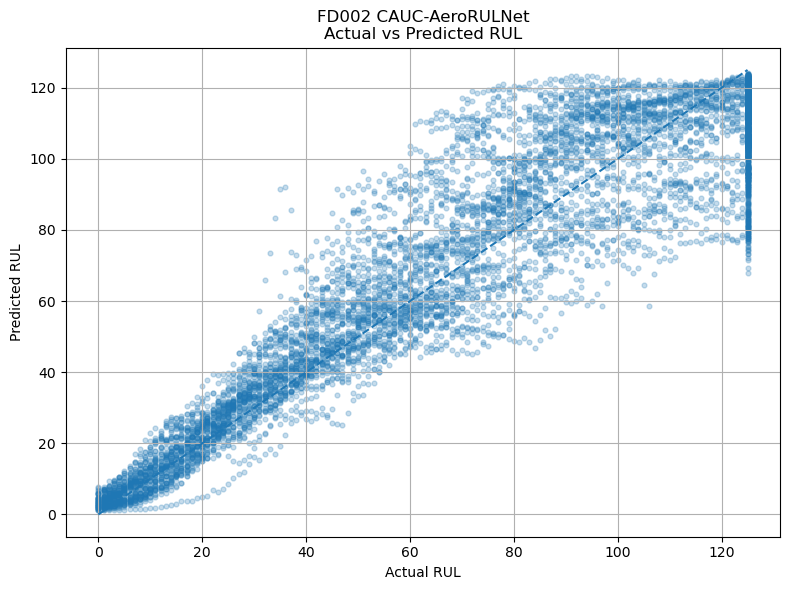

In [27]:
# ============================================================
# FD002 CAUC - ACTUAL VS PREDICTED RUL
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_cauc_val_fd002,
    pred_cauc_fd002,
    alpha=0.25,
    s=12
)

min_value = min(
    y_cauc_val_fd002.min(),
    pred_cauc_fd002.min()
)

max_value = max(
    y_cauc_val_fd002.max(),
    pred_cauc_fd002.max()
)

# Perfect prediction reference line
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "FD002 CAUC-AeroRULNet\n"
    "Actual vs Predicted RUL"
)

plt.grid()
plt.tight_layout()
plt.show()

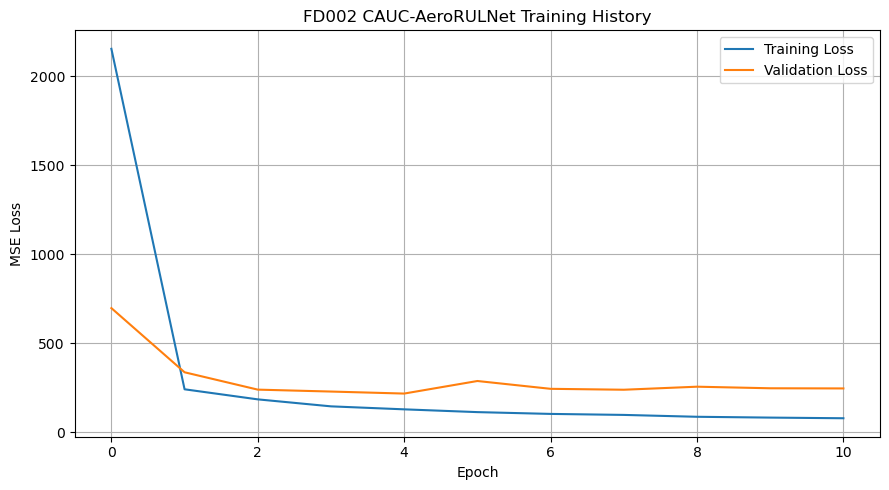

In [28]:
# ============================================================
# FD002 CAUC TRAINING HISTORY
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    history_cauc_fd002.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cauc_fd002.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "FD002 CAUC-AeroRULNet Training History"
)

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

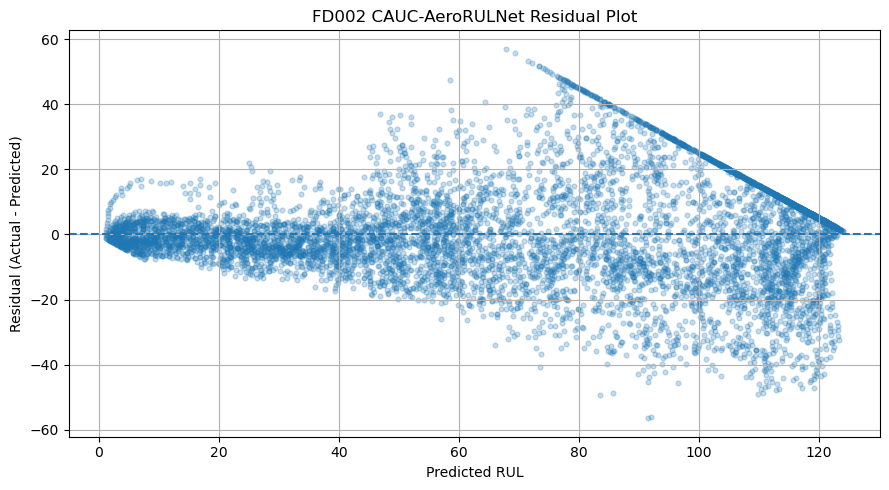

In [29]:
# ============================================================
# FD002 CAUC RESIDUAL ANALYSIS
# ============================================================

fd002_cauc_residuals = (
    y_cauc_val_fd002
    - pred_cauc_fd002
)

plt.figure(figsize=(9, 5))

plt.scatter(
    pred_cauc_fd002,
    fd002_cauc_residuals,
    alpha=0.25,
    s=12
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted RUL")
plt.ylabel("Residual (Actual - Predicted)")

plt.title(
    "FD002 CAUC-AeroRULNet Residual Plot"
)

plt.grid()
plt.tight_layout()
plt.show()

In [42]:
# ============================================================
# CAUC OPTIMIZATION EXPERIMENTS - REQUIRED IMPORTS
# ============================================================

import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    Dropout,
    Bidirectional,
    GRU,
    Dense,
    Softmax,
    Multiply,
    Lambda,
    Concatenate
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

print("✅ Optimization imports ready.")

✅ Optimization imports ready.


In [43]:
# ============================================================
# FIXED EXPERIMENT SETTINGS
# ============================================================

CAUC_SEQUENCE_LENGTH = 50

CAUC_NUM_SENSOR_FEATURES = 16

CAUC_NUM_CONDITION_FEATURES = (
    X_condition_train_fd002.shape[2]
)

CAUC_RANDOM_SEED = 42


print(
    "Sequence Length:",
    CAUC_SEQUENCE_LENGTH
)

print(
    "Sensor Features:",
    CAUC_NUM_SENSOR_FEATURES
)

print(
    "Condition Features:",
    CAUC_NUM_CONDITION_FEATURES
)

Sequence Length: 50
Sensor Features: 16
Condition Features: 3


In [46]:
# ============================================================
# CORRECTED CAUC-AeroRULNet v1
# LEARNING-RATE EXPERIMENTAL COPY
# ============================================================
# Original model architecture preserved:
#
# Sensor Input (50, 16)
#        ↓
# Multi-Scale Conv1D (3, 5, 7)
#        ↓
# Concatenate
#        ↓
# BatchNormalization
#        ↓
# Dropout
#        ↓
# Bidirectional GRU
#        ↓
# Temporal Attention
#        ↓
# Feature Attention
#        ↓
# Dense 64
#        ↓
# Dense 32
#        ↓
# RUL Prediction
#
# ONLY learning rate is configurable.
# ============================================================

def build_cauc_lr_model(
    sequence_length=50,
    num_sensor_features=16,
    learning_rate=0.001
):

    # ========================================================
    # 1. SENSOR SEQUENCE INPUT
    # ========================================================

    sensor_input = tf.keras.layers.Input(
        shape=(
            sequence_length,
            num_sensor_features
        ),
        name="sensor_sequence_input"
    )


    # ========================================================
    # 2. MULTI-SCALE TEMPORAL CONVOLUTION
    # ========================================================

    branch_3 = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu",
        name="tcn_kernel_3"
    )(sensor_input)


    branch_5 = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=5,
        padding="same",
        activation="relu",
        name="tcn_kernel_5"
    )(sensor_input)


    branch_7 = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=7,
        padding="same",
        activation="relu",
        name="tcn_kernel_7"
    )(sensor_input)


    # ========================================================
    # 3. MULTI-SCALE FUSION
    # ========================================================

    x = tf.keras.layers.Concatenate(
        axis=-1,
        name="multi_scale_fusion"
    )([
        branch_3,
        branch_5,
        branch_7
    ])


    # ========================================================
    # 4. BATCH NORMALIZATION
    # ========================================================

    x = tf.keras.layers.BatchNormalization(
        name="multi_scale_batchnorm"
    )(x)


    # ========================================================
    # 5. DROPOUT
    # ========================================================

    x = tf.keras.layers.Dropout(
        0.20,
        name="multi_scale_dropout"
    )(x)


    # ========================================================
    # 6. BIDIRECTIONAL GRU
    # ========================================================

    x = tf.keras.layers.Bidirectional(

        tf.keras.layers.GRU(
            64,
            return_sequences=True
        ),

        name="bidirectional_gru"

    )(x)


    # ========================================================
    # 7. BiGRU DROPOUT
    # ========================================================

    x = tf.keras.layers.Dropout(
        0.20,
        name="bigru_dropout"
    )(x)


    # ========================================================
    # 8. TEMPORAL ATTENTION SCORES
    # ========================================================

    temporal_scores = tf.keras.layers.Dense(
        1
    )(x)


    # ========================================================
    # 9. TEMPORAL ATTENTION WEIGHTS
    # ========================================================

    temporal_weights = tf.keras.layers.Softmax(
        axis=1,
        name="temporal_attention_weights"
    )(temporal_scores)


    # ========================================================
    # 10. APPLY TEMPORAL ATTENTION
    # ========================================================

    weighted_sequence = tf.keras.layers.Multiply()([
        x,
        temporal_weights
    ])


    # ========================================================
    # 11. TEMPORAL CONTEXT VECTOR
    # ========================================================

    temporal_context = tf.keras.layers.Lambda(

        lambda tensor:
            tf.reduce_sum(
                tensor,
                axis=1
            ),

        name="temporal_context"

    )(weighted_sequence)


    # ========================================================
    # 12. FEATURE ATTENTION
    # ========================================================
    # BiGRU output = 128 dimensions.
    # Generate one attention weight per dimension.
    # ========================================================

    feature_attention = tf.keras.layers.Dense(
        128,
        activation="sigmoid",
        name="feature_attention_weights"
    )(temporal_context)


    feature_context = tf.keras.layers.Multiply()([
        temporal_context,
        feature_attention
    ])


    # ========================================================
    # 13. DENSE REGRESSION HEAD
    # ========================================================

    x = tf.keras.layers.Dense(
        64,
        activation="relu",
        name="dense_64"
    )(feature_context)


    x = tf.keras.layers.Dropout(
        0.20,
        name="dense_dropout"
    )(x)


    x = tf.keras.layers.Dense(
        32,
        activation="relu",
        name="dense_32"
    )(x)


    # ========================================================
    # 14. RUL OUTPUT
    # ========================================================

    output = tf.keras.layers.Dense(
        1,
        activation="linear",
        name="rul_prediction"
    )(x)


    # ========================================================
    # 15. CREATE MODEL
    # ========================================================

    model = tf.keras.Model(
        inputs=sensor_input,
        outputs=output,
        name="CAUC_AeroRULNet_LR_Experiment"
    )


    # ========================================================
    # 16. COMPILE
    # ========================================================

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),

        loss="mse",

        metrics=["mae"]
    )


    return model

In [47]:
# ============================================================
# VERIFY CORRECTED EXPERIMENTAL ARCHITECTURE
# ============================================================

tf.keras.backend.clear_session()


cauc_lr_test = build_cauc_lr_model(

    sequence_length=50,

    num_sensor_features=16,

    learning_rate=0.0005

)


print("=" * 60)

print(
    "CAUC-AeroRULNet Architecture Verification"
)

print("=" * 60)


print(
    "Experimental Parameters:",
    cauc_lr_test.count_params()
)


print(
    "Expected Original Parameters:",
    97378
)


print(
    "Learning Rate:",
    float(
        tf.keras.backend.get_value(
            cauc_lr_test.optimizer.learning_rate
        )
    )
)


if cauc_lr_test.count_params() == 97378:

    print(
        "\n✅ PERFECT: Architecture matches original CAUC v1."
    )

    print(
        "Learning-rate experiments can now start."
    )

else:

    print(
        "\n❌ STOP: Architecture still does not match."
    )

    print(
        "Do NOT start training."
    )

CAUC-AeroRULNet Architecture Verification
Experimental Parameters: 97378
Expected Original Parameters: 97378
Learning Rate: 0.0005000000237487257

✅ PERFECT: Architecture matches original CAUC v1.
Learning-rate experiments can now start.


In [48]:
# ============================================================
# FORWARD PASS TEST
# ============================================================
# Purpose:
# Confirm that the exact-match experimental CAUC model
# accepts the same sensor sequence input as the original model.
# ============================================================

sample_predictions = cauc_lr_test.predict(
    X_sensor_train_fd002[:5],
    verbose=0
)

print(
    "Input Shape:",
    X_sensor_train_fd002[:5].shape
)

print(
    "Output Shape:",
    sample_predictions.shape
)

print(
    "Sample Predictions:"
)

print(
    sample_predictions.reshape(-1)
)

Input Shape: (5, 50, 16)
Output Shape: (5, 1)
Sample Predictions:
[0.06155384 0.06098035 0.06201348 0.06667387 0.06336692]


In [49]:
# ============================================================
# LEARNING RATE CANDIDATES
# ============================================================
# Original:
# 0.001 → RMSE 14.7321
#
# Now test smaller learning rates.
# ============================================================

learning_rates = [
    0.0005,
    0.0003
]

print(
    "Learning rates to test:",
    learning_rates
)

Learning rates to test: [0.0005, 0.0003]


In [50]:
# ============================================================
# LEARNING-RATE EXPERIMENT CALLBACKS
# ============================================================
# EarlyStopping:
# Stops training when validation performance stops improving.
#
# ReduceLROnPlateau:
# Further reduces LR if optimization becomes stuck.
# ============================================================

def create_cauc_lr_callbacks():

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=7,
        min_delta=0.001,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )

    return [
        early_stopping,
        reduce_lr
    ]

In [51]:
# ============================================================
# TRAIN ONE CAUC LEARNING-RATE CONFIGURATION
# ============================================================
# IMPORTANT:
# Architecture remains identical.
# Only learning rate changes.
# ============================================================

def run_cauc_lr_experiment(
    learning_rate
):

    # ========================================================
    # RESET TENSORFLOW STATE
    # ========================================================

    tf.keras.backend.clear_session()

    random.seed(
        CAUC_RANDOM_SEED
    )

    np.random.seed(
        CAUC_RANDOM_SEED
    )

    tf.random.set_seed(
        CAUC_RANDOM_SEED
    )


    # ========================================================
    # BUILD EXACT-MATCH CAUC MODEL
    # ========================================================

    model = build_cauc_lr_model(

        sequence_length=
            CAUC_SEQUENCE_LENGTH,

        num_sensor_features=
            CAUC_NUM_SENSOR_FEATURES,

        learning_rate=
            learning_rate
    )


    # Safety check:
    # architecture must remain identical
    if model.count_params() != 97378:

        raise ValueError(
            "Architecture mismatch! "
            f"Expected 97378 parameters, "
            f"got {model.count_params()}."
        )


    print("\n" + "=" * 70)

    print(
        f"FD002 CAUC LR EXPERIMENT "
        f"| Learning Rate = {learning_rate}"
    )

    print("=" * 70)


    # ========================================================
    # TRAINING
    # ========================================================

    training_start = time.time()


    history = model.fit(

        X_sensor_train_fd002,

        y_cauc_train_fd002,


        validation_data=(

            X_sensor_val_fd002,

            y_cauc_val_fd002
        ),


        epochs=50,

        batch_size=256,

        callbacks=
            create_cauc_lr_callbacks(),

        verbose=1
    )


    training_time = (
        time.time()
        -
        training_start
    )


    # ========================================================
    # VALIDATION PREDICTIONS
    # ========================================================

    prediction_start = time.time()


    predictions = model.predict(

        X_sensor_val_fd002,

        batch_size=256,

        verbose=0

    ).reshape(-1)


    inference_time = (
        time.time()
        -
        prediction_start
    )


    # ========================================================
    # METRICS
    # ========================================================

    mae = mean_absolute_error(
        y_cauc_val_fd002,
        predictions
    )


    mse = mean_squared_error(
        y_cauc_val_fd002,
        predictions
    )


    rmse = np.sqrt(
        mse
    )


    r2 = r2_score(
        y_cauc_val_fd002,
        predictions
    )


    # ========================================================
    # BEST EPOCH INFORMATION
    # ========================================================

    best_epoch = (
        np.argmin(
            history.history[
                "val_loss"
            ]
        )
        + 1
    )


    best_val_loss = (
        np.min(
            history.history[
                "val_loss"
            ]
        )
    )


    # ========================================================
    # SAVE RESULTS
    # ========================================================

    result = {

        "Learning_Rate":
            learning_rate,

        "MAE":
            mae,

        "MSE":
            mse,

        "RMSE":
            rmse,

        "R2":
            r2,

        "Best_Epoch":
            best_epoch,

        "Best_Val_Loss":
            best_val_loss,

        "Epochs_Trained":
            len(
                history.history[
                    "loss"
                ]
            ),

        "Training_Time_sec":
            training_time,

        "Inference_Time_sec":
            inference_time
    }


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print("\nFINAL RESULT")

    print(
        f"Learning Rate : {learning_rate}"
    )

    print(
        f"MAE           : {mae:.4f}"
    )

    print(
        f"RMSE          : {rmse:.4f}"
    )

    print(
        f"R²            : {r2:.4f}"
    )

    print(
        f"Best Epoch    : {best_epoch}"
    )

    print(
        f"Epochs Trained: "
        f"{len(history.history['loss'])}"
    )


    return (
        model,
        history,
        predictions,
        result
    )

In [52]:
# ============================================================
# EXPERIMENT 1
# CAUC Learning Rate = 0.0005
# ============================================================

(
    cauc_lr_0005,
    history_lr_0005,
    pred_lr_0005,
    result_lr_0005

) = run_cauc_lr_experiment(

    learning_rate=0.0005
)


FD002 CAUC LR EXPERIMENT | Learning Rate = 0.0005
Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 43s 241ms/step - loss: 3536.5981 - mae: 47.6212 - val_loss: 1026.0491 - val_mae: 26.9359 - learning_rate: 5.0000e-04
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 28s 215ms/step - loss: 681.2423 - mae: 21.1360 - val_loss: 429.2489 - val_mae: 16.4033 - learning_rate: 5.0000e-04
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 40s 204ms/step - loss: 379.8341 - mae: 15.3032 - val_loss: 273.1702 - val_mae: 13.0017 - learning_rate: 5.0000e-04
Epoch 4/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 43s 215ms/step - loss: 276.7284 - mae: 12.7497 - val_loss: 198.8016 - val_mae: 11.0819 - learning_rate: 5.0000e-04
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 40s 204ms/step - loss: 235.7380 - mae: 11.6571 - val_loss: 181.2447 - val_mae: 10.4700 - learning_rate: 5.0000e-04
Epoch 6/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 28s 213ms/step - loss: 206.7621 - mae: 10.8461 - val_loss: 191.9198 - val_mae: 10.5055 - learning_rate: 5.0000e-04
Epoch 7/50
130/13

In [53]:
# ============================================================
# EXPERIMENT 2
# CAUC Learning Rate = 0.0003
# ============================================================

(
    cauc_lr_0003,
    history_lr_0003,
    pred_lr_0003,
    result_lr_0003

) = run_cauc_lr_experiment(

    learning_rate=0.0003
)


FD002 CAUC LR EXPERIMENT | Learning Rate = 0.0003
Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 43s 245ms/step - loss: 4736.0415 - mae: 57.5183 - val_loss: 1193.5646 - val_mae: 29.1990 - learning_rate: 3.0000e-04
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 30s 228ms/step - loss: 1003.9811 - mae: 26.5164 - val_loss: 621.3947 - val_mae: 20.7259 - learning_rate: 3.0000e-04
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 37s 199ms/step - loss: 537.2289 - mae: 18.6095 - val_loss: 399.5481 - val_mae: 15.8301 - learning_rate: 3.0000e-04
Epoch 4/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 43s 215ms/step - loss: 380.7455 - mae: 15.2864 - val_loss: 272.5546 - val_mae: 13.3805 - learning_rate: 3.0000e-04
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 29s 220ms/step - loss: 300.2780 - mae: 13.3336 - val_loss: 215.3788 - val_mae: 11.5676 - learning_rate: 3.0000e-04
Epoch 6/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 30s 231ms/step - loss: 261.2445 - mae: 12.3109 - val_loss: 202.9955 - val_mae: 10.8203 - learning_rate: 3.0000e-04
Epoch 7/50
130/1

In [54]:
# ============================================================
# ORIGINAL CAUC v1 RESULT
# ============================================================

original_cauc_result = {

    "Configuration":
        "Original CAUC",

    "Learning_Rate":
        0.001,

    "MAE":
        10.828442573547363,

    "RMSE":
        14.7320758081537,

    "R2":
        0.870505154132843,

    "Best_Epoch":
        5
}

In [55]:
# ============================================================
# PREPARE LEARNING-RATE EXPERIMENT RESULTS
# ============================================================

lr_0005_result = {

    "Configuration":
        "CAUC LR 0.0005",

    "Learning_Rate":
        result_lr_0005[
            "Learning_Rate"
        ],

    "MAE":
        result_lr_0005[
            "MAE"
        ],

    "RMSE":
        result_lr_0005[
            "RMSE"
        ],

    "R2":
        result_lr_0005[
            "R2"
        ],

    "Best_Epoch":
        result_lr_0005[
            "Best_Epoch"
        ]
}


lr_0003_result = {

    "Configuration":
        "CAUC LR 0.0003",

    "Learning_Rate":
        result_lr_0003[
            "Learning_Rate"
        ],

    "MAE":
        result_lr_0003[
            "MAE"
        ],

    "RMSE":
        result_lr_0003[
            "RMSE"
        ],

    "R2":
        result_lr_0003[
            "R2"
        ],

    "Best_Epoch":
        result_lr_0003[
            "Best_Epoch"
        ]
}

In [56]:
# ============================================================
# CAUC LEARNING-RATE COMPARISON
# ============================================================

cauc_lr_comparison = pd.DataFrame([

    original_cauc_result,

    lr_0005_result,

    lr_0003_result
])


# Best RMSE first
cauc_lr_comparison = (
    cauc_lr_comparison
    .sort_values(
        "RMSE"
    )
    .reset_index(
        drop=True
    )
)


display(
    cauc_lr_comparison
)

,Configuration,Learning_Rate,MAE,RMSE,R2,Best_Epoch
0,CAUC LR 0.0005,0.0005,10.469964,13.462717,0.891859,5
1,CAUC LR 0.0003,0.0003,10.262185,13.479846,0.891584,8
2,Original CAUC,0.0010,10.828443,14.732076,0.870505,5


In [57]:
# ============================================================
# BEST CAUC VS BiLSTM BASELINE
# ============================================================

BILSTM_FD002_RMSE = 14.169504


best_cauc_row = (
    cauc_lr_comparison
    .iloc[0]
)


best_cauc_rmse = (
    best_cauc_row[
        "RMSE"
    ]
)


print("=" * 65)

print(
    "FD002 MODEL COMPARISON"
)

print("=" * 65)


print(
    "Best CAUC Configuration:",
    best_cauc_row[
        "Configuration"
    ]
)


print(
    f"Best CAUC RMSE : "
    f"{best_cauc_rmse:.4f}"
)


print(
    f"BiLSTM RMSE    : "
    f"{BILSTM_FD002_RMSE:.4f}"
)

FD002 MODEL COMPARISON
Best CAUC Configuration: CAUC LR 0.0005
Best CAUC RMSE : 13.4627
BiLSTM RMSE    : 14.1695


In [58]:
# ============================================================
# IMPROVEMENT VS BiLSTM
# ============================================================

rmse_improvement = (

    (
        BILSTM_FD002_RMSE
        -
        best_cauc_rmse
    )

    /

    BILSTM_FD002_RMSE

) * 100


print(
    f"CAUC Improvement vs BiLSTM: "
    f"{rmse_improvement:.2f}%"
)


if best_cauc_rmse < BILSTM_FD002_RMSE:

    print(
        "\n🏆 CAUC currently beats "
        "the BiLSTM baseline."
    )

else:

    print(
        "\nBiLSTM is still better."
    )

CAUC Improvement vs BiLSTM: 4.99%

🏆 CAUC currently beats the BiLSTM baseline.


In [59]:
# ============================================================
# LOCK BEST CAUC LEARNING RATE
# ============================================================

BEST_CAUC_LEARNING_RATE = 0.0005

print(
    "Best CAUC Learning Rate:",
    BEST_CAUC_LEARNING_RATE
)

Best CAUC Learning Rate: 0.0005


In [60]:
# ============================================================
# SAVE CURRENT BEST FD002 CAUC MODEL
# ============================================================

MODEL_DIR = (
    r"D:\IST\Aircraft_Engine_RUL\models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

BEST_FD002_CAUC_PATH = os.path.join(
    MODEL_DIR,
    "cauc_aerorulnet_fd002_best_lr.keras"
)

cauc_lr_0005.save(
    BEST_FD002_CAUC_PATH
)

print("✅ Best FD002 CAUC model saved:")
print(BEST_FD002_CAUC_PATH)

✅ Best FD002 CAUC model saved:
D:\IST\Aircraft_Engine_RUL\models\cauc_aerorulnet_fd002_best_lr.keras


In [61]:
# ============================================================
# CAUC-AeroRULNet
# DROPOUT ABLATION BUILDER
# ============================================================
# CONTROLLED EXPERIMENT
#
# Fixed:
#   Sequence Length = 50
#   Sensors         = 16
#   Learning Rate   = 0.0005
#   Architecture    = SAME
#
# Variable:
#   Dropout Rate
# ============================================================

def build_cauc_dropout_model(
    sequence_length=50,
    num_sensor_features=16,
    learning_rate=0.0005,
    dropout_rate=0.20
):

    # ========================================================
    # 1. SENSOR INPUT
    # ========================================================

    sensor_input = tf.keras.layers.Input(
        shape=(
            sequence_length,
            num_sensor_features
        ),
        name="sensor_sequence_input"
    )


    # ========================================================
    # 2. MULTI-SCALE TEMPORAL CONVOLUTION
    # ========================================================

    branch_3 = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu",
        name="tcn_kernel_3"
    )(sensor_input)


    branch_5 = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=5,
        padding="same",
        activation="relu",
        name="tcn_kernel_5"
    )(sensor_input)


    branch_7 = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=7,
        padding="same",
        activation="relu",
        name="tcn_kernel_7"
    )(sensor_input)


    # ========================================================
    # 3. MULTI-SCALE FUSION
    # ========================================================

    x = tf.keras.layers.Concatenate(
        axis=-1,
        name="multi_scale_fusion"
    )([
        branch_3,
        branch_5,
        branch_7
    ])


    # ========================================================
    # 4. BATCH NORMALIZATION
    # ========================================================

    x = tf.keras.layers.BatchNormalization(
        name="multi_scale_batchnorm"
    )(x)


    # ========================================================
    # 5. MULTI-SCALE DROPOUT
    # ========================================================

    x = tf.keras.layers.Dropout(
        dropout_rate,
        name="multi_scale_dropout"
    )(x)


    # ========================================================
    # 6. BIDIRECTIONAL GRU
    # ========================================================

    x = tf.keras.layers.Bidirectional(

        tf.keras.layers.GRU(
            64,
            return_sequences=True
        ),

        name="bidirectional_gru"

    )(x)


    # ========================================================
    # 7. BiGRU DROPOUT
    # ========================================================

    x = tf.keras.layers.Dropout(
        dropout_rate,
        name="bigru_dropout"
    )(x)


    # ========================================================
    # 8. TEMPORAL ATTENTION SCORES
    # ========================================================

    temporal_scores = tf.keras.layers.Dense(
        1
    )(x)


    # ========================================================
    # 9. TEMPORAL ATTENTION WEIGHTS
    # ========================================================

    temporal_weights = tf.keras.layers.Softmax(
        axis=1,
        name="temporal_attention_weights"
    )(temporal_scores)


    # ========================================================
    # 10. TEMPORAL WEIGHTING
    # ========================================================

    weighted_sequence = tf.keras.layers.Multiply()([
        x,
        temporal_weights
    ])


    # ========================================================
    # 11. TEMPORAL CONTEXT
    # ========================================================

    temporal_context = tf.keras.layers.Lambda(

        lambda tensor:
            tf.reduce_sum(
                tensor,
                axis=1
            ),

        name="temporal_context"

    )(weighted_sequence)


    # ========================================================
    # 12. FEATURE ATTENTION
    # ========================================================

    feature_attention = tf.keras.layers.Dense(
        128,
        activation="sigmoid",
        name="feature_attention_weights"
    )(temporal_context)


    feature_context = tf.keras.layers.Multiply()([
        temporal_context,
        feature_attention
    ])


    # ========================================================
    # 13. DENSE REGRESSION HEAD
    # ========================================================

    x = tf.keras.layers.Dense(
        64,
        activation="relu",
        name="dense_64"
    )(feature_context)


    # ========================================================
    # 14. DENSE DROPOUT
    # ========================================================

    x = tf.keras.layers.Dropout(
        dropout_rate,
        name="dense_dropout"
    )(x)


    x = tf.keras.layers.Dense(
        32,
        activation="relu",
        name="dense_32"
    )(x)


    # ========================================================
    # 15. RUL PREDICTION
    # ========================================================

    output = tf.keras.layers.Dense(
        1,
        activation="linear",
        name="rul_prediction"
    )(x)


    # ========================================================
    # 16. CREATE MODEL
    # ========================================================

    model = tf.keras.Model(
        inputs=sensor_input,
        outputs=output,
        name="CAUC_AeroRULNet_Dropout_Experiment"
    )


    # ========================================================
    # 17. COMPILE
    # ========================================================

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),

        loss="mse",

        metrics=["mae"]
    )


    return model

In [62]:
# ============================================================
# DROPOUT MODEL ARCHITECTURE VERIFICATION
# ============================================================

tf.keras.backend.clear_session()


dropout_test_model = build_cauc_dropout_model(

    sequence_length=50,

    num_sensor_features=16,

    learning_rate=0.0005,

    dropout_rate=0.10
)


EXPECTED_PARAMETERS = 97378


print("=" * 60)

print(
    "CAUC Dropout Experiment Verification"
)

print("=" * 60)


print(
    "Parameters:",
    dropout_test_model.count_params()
)


print(
    "Expected:",
    EXPECTED_PARAMETERS
)


if dropout_test_model.count_params() == EXPECTED_PARAMETERS:

    print(
        "\n✅ Architecture preserved."
    )

else:

    print(
        "\n❌ Architecture mismatch."
    )

    print(
        "STOP before training."
    )

CAUC Dropout Experiment Verification
Parameters: 97378
Expected: 97378

✅ Architecture preserved.


In [63]:
# ============================================================
# DROPOUT EXPERIMENT CALLBACKS
# ============================================================

def create_dropout_callbacks():

    early_stopping = tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=7,

        min_delta=0.001,

        restore_best_weights=True,

        verbose=1
    )


    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=4,

        min_lr=1e-6,

        verbose=1
    )


    return [
        early_stopping,
        reduce_lr
    ]

In [64]:
# ============================================================
# TRAIN ONE DROPOUT CONFIGURATION
# ============================================================

def run_cauc_dropout_experiment(
    dropout_rate
):

    # ========================================================
    # 1. RESET
    # ========================================================

    tf.keras.backend.clear_session()


    random.seed(
        CAUC_RANDOM_SEED
    )

    np.random.seed(
        CAUC_RANDOM_SEED
    )

    tf.random.set_seed(
        CAUC_RANDOM_SEED
    )


    # ========================================================
    # 2. BUILD MODEL
    # ========================================================

    model = build_cauc_dropout_model(

        sequence_length=
            CAUC_SEQUENCE_LENGTH,

        num_sensor_features=
            CAUC_NUM_SENSOR_FEATURES,

        learning_rate=
            BEST_CAUC_LEARNING_RATE,

        dropout_rate=
            dropout_rate
    )


    # ========================================================
    # 3. ARCHITECTURE SAFETY CHECK
    # ========================================================

    if model.count_params() != 97378:

        raise ValueError(

            "Architecture mismatch! "

            f"Expected 97378 parameters, "

            f"got {model.count_params()}."
        )


    print("\n" + "=" * 70)

    print(
        f"FD002 CAUC DROPOUT EXPERIMENT "
        f"| Dropout = {dropout_rate}"
    )

    print(
        f"Learning Rate = "
        f"{BEST_CAUC_LEARNING_RATE}"
    )

    print("=" * 70)


    # ========================================================
    # 4. TRAIN
    # ========================================================

    training_start = time.time()


    history = model.fit(

        X_sensor_train_fd002,

        y_cauc_train_fd002,


        validation_data=(

            X_sensor_val_fd002,

            y_cauc_val_fd002
        ),


        epochs=50,

        batch_size=256,

        callbacks=
            create_dropout_callbacks(),

        verbose=1
    )


    training_time = (
        time.time()
        -
        training_start
    )


    # ========================================================
    # 5. PREDICT
    # ========================================================

    inference_start = time.time()


    predictions = model.predict(

        X_sensor_val_fd002,

        batch_size=256,

        verbose=0

    ).reshape(-1)


    inference_time = (
        time.time()
        -
        inference_start
    )


    # ========================================================
    # 6. METRICS
    # ========================================================

    mae = mean_absolute_error(
        y_cauc_val_fd002,
        predictions
    )


    mse = mean_squared_error(
        y_cauc_val_fd002,
        predictions
    )


    rmse = np.sqrt(
        mse
    )


    r2 = r2_score(
        y_cauc_val_fd002,
        predictions
    )


    # ========================================================
    # 7. BEST EPOCH
    # ========================================================

    best_epoch = (
        np.argmin(
            history.history["val_loss"]
        )
        + 1
    )


    best_val_loss = (
        np.min(
            history.history["val_loss"]
        )
    )


    # ========================================================
    # 8. RESULT
    # ========================================================

    result = {

        "Dropout":
            dropout_rate,

        "Learning_Rate":
            BEST_CAUC_LEARNING_RATE,

        "MAE":
            mae,

        "MSE":
            mse,

        "RMSE":
            rmse,

        "R2":
            r2,

        "Best_Epoch":
            best_epoch,

        "Best_Val_Loss":
            best_val_loss,

        "Epochs_Trained":
            len(
                history.history["loss"]
            ),

        "Training_Time_sec":
            training_time,

        "Inference_Time_sec":
            inference_time
    }


    # ========================================================
    # 9. PRINT
    # ========================================================

    print("\nFINAL RESULT")

    print(
        f"Dropout       : {dropout_rate}"
    )

    print(
        f"Learning Rate : "
        f"{BEST_CAUC_LEARNING_RATE}"
    )

    print(
        f"MAE           : {mae:.4f}"
    )

    print(
        f"RMSE          : {rmse:.4f}"
    )

    print(
        f"R²            : {r2:.4f}"
    )

    print(
        f"Best Epoch    : {best_epoch}"
    )

    print(
        f"Epochs Trained: "
        f"{len(history.history['loss'])}"
    )


    return (
        model,
        history,
        predictions,
        result
    )

In [65]:
# ============================================================
# DROPOUT EXPERIMENT 1
# Dropout = 0.10
# ============================================================

(
    cauc_dropout_010,
    history_dropout_010,
    pred_dropout_010,
    result_dropout_010

) = run_cauc_dropout_experiment(

    dropout_rate=0.10
)


FD002 CAUC DROPOUT EXPERIMENT | Dropout = 0.1
Learning Rate = 0.0005
Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 43s 254ms/step - loss: 3523.1516 - mae: 47.5819 - val_loss: 1011.6125 - val_mae: 26.8134 - learning_rate: 5.0000e-04
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 35s 208ms/step - loss: 616.0516 - mae: 20.2027 - val_loss: 453.3517 - val_mae: 16.7428 - learning_rate: 5.0000e-04
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 42s 214ms/step - loss: 333.7865 - mae: 14.2704 - val_loss: 245.2490 - val_mae: 12.3785 - learning_rate: 5.0000e-04
Epoch 4/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 41s 209ms/step - loss: 227.2408 - mae: 11.4776 - val_loss: 195.2859 - val_mae: 10.9242 - learning_rate: 5.0000e-04
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 42s 214ms/step - loss: 188.6196 - mae: 10.3843 - val_loss: 190.3524 - val_mae: 10.6701 - learning_rate: 5.0000e-04
Epoch 6/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 41s 214ms/step - loss: 156.6038 - mae: 9.3974 - val_loss: 186.5683 - val_mae: 10.3769 - learning_rate: 5.0000e-04

In [66]:
# ============================================================
# DROPOUT EXPERIMENT 2
# Dropout = 0.30
# ============================================================

(
    cauc_dropout_030,
    history_dropout_030,
    pred_dropout_030,
    result_dropout_030

) = run_cauc_dropout_experiment(

    dropout_rate=0.30
)


FD002 CAUC DROPOUT EXPERIMENT | Dropout = 0.3
Learning Rate = 0.0005
Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 42s 257ms/step - loss: 3508.0125 - mae: 47.3099 - val_loss: 1012.4055 - val_mae: 26.7201 - learning_rate: 5.0000e-04
Epoch 2/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 31s 238ms/step - loss: 757.0240 - mae: 22.3327 - val_loss: 427.9119 - val_mae: 16.6252 - learning_rate: 5.0000e-04
Epoch 3/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 39s 221ms/step - loss: 430.9699 - mae: 16.3079 - val_loss: 267.4691 - val_mae: 12.8694 - learning_rate: 5.0000e-04
Epoch 4/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 30s 231ms/step - loss: 325.1222 - mae: 13.7759 - val_loss: 192.6666 - val_mae: 10.7579 - learning_rate: 5.0000e-04
Epoch 5/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 42s 237ms/step - loss: 281.2508 - mae: 12.7235 - val_loss: 182.0444 - val_mae: 10.4390 - learning_rate: 5.0000e-04
Epoch 6/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 39s 219ms/step - loss: 257.5960 - mae: 12.1130 - val_loss: 187.4262 - val_mae: 10.5483 - learning_rate: 5.0000e-0

In [67]:
# ============================================================
# CURRENT DROPOUT 0.20 RESULT
# ============================================================

current_dropout_result = {

    "Configuration":
        "Dropout 0.20",

    "Dropout":
        0.20,

    "Learning_Rate":
        0.0005,

    "MAE":
        10.469964,

    "RMSE":
        13.462717,

    "R2":
        0.891859,

    "Best_Epoch":
        5
}

In [68]:
# ============================================================
# PREPARE DROPOUT RESULTS
# ============================================================

dropout_010_result = {

    "Configuration":
        "Dropout 0.10",

    "Dropout":
        0.10,

    "Learning_Rate":
        result_dropout_010[
            "Learning_Rate"
        ],

    "MAE":
        result_dropout_010[
            "MAE"
        ],

    "RMSE":
        result_dropout_010[
            "RMSE"
        ],

    "R2":
        result_dropout_010[
            "R2"
        ],

    "Best_Epoch":
        result_dropout_010[
            "Best_Epoch"
        ]
}


dropout_030_result = {

    "Configuration":
        "Dropout 0.30",

    "Dropout":
        0.30,

    "Learning_Rate":
        result_dropout_030[
            "Learning_Rate"
        ],

    "MAE":
        result_dropout_030[
            "MAE"
        ],

    "RMSE":
        result_dropout_030[
            "RMSE"
        ],

    "R2":
        result_dropout_030[
            "R2"
        ],

    "Best_Epoch":
        result_dropout_030[
            "Best_Epoch"
        ]
}

In [69]:
# ============================================================
# DROPOUT ABLATION COMPARISON
# ============================================================

dropout_comparison_df = pd.DataFrame([

    dropout_010_result,

    current_dropout_result,

    dropout_030_result

])


dropout_comparison_df = (

    dropout_comparison_df

    .sort_values(
        "RMSE"
    )

    .reset_index(
        drop=True
    )

)


display(
    dropout_comparison_df
)

,Configuration,Dropout,Learning_Rate,MAE,RMSE,R2,Best_Epoch
0,Dropout 0.30,0.3,0.0005,10.109778,13.442931,0.892177,7
1,Dropout 0.20,0.2,0.0005,10.469964,13.462717,0.891859,5
2,Dropout 0.10,0.1,0.0005,10.376875,13.659000,0.888683,6


In [70]:
# ============================================================
# SELECT BEST DROPOUT
# ============================================================

best_dropout_row = (
    dropout_comparison_df
    .iloc[0]
)


BEST_CAUC_DROPOUT = float(
    best_dropout_row[
        "Dropout"
    ]
)


BEST_CAUC_RMSE = float(
    best_dropout_row[
        "RMSE"
    ]
)


print("=" * 65)

print(
    "BEST CAUC DROPOUT CONFIGURATION"
)

print("=" * 65)


print(
    "Best Dropout:",
    BEST_CAUC_DROPOUT
)


print(
    f"RMSE : "
    f"{BEST_CAUC_RMSE:.4f}"
)


print(
    f"MAE  : "
    f"{best_dropout_row['MAE']:.4f}"
)


print(
    f"R²   : "
    f"{best_dropout_row['R2']:.4f}"
)


print(
    "\nLocked Learning Rate:",
    BEST_CAUC_LEARNING_RATE
)

BEST CAUC DROPOUT CONFIGURATION
Best Dropout: 0.3
RMSE : 13.4429
MAE  : 10.1098
R²   : 0.8922

Locked Learning Rate: 0.0005


In [71]:
# ============================================================
# FINAL CURRENT COMPARISON
# ============================================================

BILSTM_FD002_RMSE = 14.169504


improvement_vs_bilstm = (

    (
        BILSTM_FD002_RMSE
        -
        BEST_CAUC_RMSE
    )

    /

    BILSTM_FD002_RMSE

) * 100


print(
    f"BiLSTM RMSE : "
    f"{BILSTM_FD002_RMSE:.4f}"
)


print(
    f"CAUC RMSE   : "
    f"{BEST_CAUC_RMSE:.4f}"
)


print(
    f"Improvement : "
    f"{improvement_vs_bilstm:.2f}%"
)


if BEST_CAUC_RMSE < BILSTM_FD002_RMSE:

    print(
        "\n🏆 CAUC-AeroRULNet "
        "beats BiLSTM."
    )

else:

    print(
        "\nBiLSTM remains better."
    )

BiLSTM RMSE : 14.1695
CAUC RMSE   : 13.4429
Improvement : 5.13%

🏆 CAUC-AeroRULNet beats BiLSTM.


In [72]:
# ============================================================
# LOCK CURRENT BEST CAUC CONFIGURATION
# ============================================================

BEST_CAUC_LEARNING_RATE = 0.0005
BEST_CAUC_DROPOUT = 0.30

CURRENT_BEST_CAUC_RMSE = 13.442931
CURRENT_BEST_CAUC_MAE = 10.109778
CURRENT_BEST_CAUC_R2 = 0.892177

print("Current Best CAUC Configuration")
print("Learning Rate :", BEST_CAUC_LEARNING_RATE)
print("Dropout       :", BEST_CAUC_DROPOUT)
print("RMSE          :", CURRENT_BEST_CAUC_RMSE)
print("MAE           :", CURRENT_BEST_CAUC_MAE)
print("R²            :", CURRENT_BEST_CAUC_R2)

Current Best CAUC Configuration
Learning Rate : 0.0005
Dropout       : 0.3
RMSE          : 13.442931
MAE           : 10.109778
R²            : 0.892177


In [73]:
# ============================================================
# SAVE CURRENT BEST FD002 CAUC-AeroRULNet
# ============================================================

MODEL_DIR = r"D:\IST\Aircraft_Engine_RUL\models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

BEST_CAUC_FD002_PATH = os.path.join(
    MODEL_DIR,
    "cauc_aerorulnet_fd002_best.keras"
)

cauc_dropout_030.save(
    BEST_CAUC_FD002_PATH
)

print("✅ Best FD002 CAUC model saved.")
print(BEST_CAUC_FD002_PATH)

✅ Best FD002 CAUC model saved.
D:\IST\Aircraft_Engine_RUL\models\cauc_aerorulnet_fd002_best.keras


In [74]:
# ============================================================
# TRAIN FINAL LOCKED CAUC-AeroRULNet ON FD003
# ============================================================
# IMPORTANT:
# No hyperparameter tuning is performed on FD003.
#
# We directly use the configuration selected on FD002:
# Learning Rate = 0.0005
# Dropout       = 0.30
# Sequence      = 50
# Sensors       = 16
#
# This provides a cleaner cross-dataset validation.
# ============================================================

# ------------------------------------------------------------
# Reset TensorFlow state
# ------------------------------------------------------------

tf.keras.backend.clear_session()

random.seed(CAUC_RANDOM_SEED)
np.random.seed(CAUC_RANDOM_SEED)
tf.random.set_seed(CAUC_RANDOM_SEED)


# ------------------------------------------------------------
# Build model using LOCKED FD002 configuration
# ------------------------------------------------------------

cauc_fd003_final = build_cauc_dropout_model(

    sequence_length=
        CAUC_SEQUENCE_LENGTH,

    num_sensor_features=
        CAUC_NUM_SENSOR_FEATURES,

    learning_rate=
        BEST_CAUC_LEARNING_RATE,

    dropout_rate=
        BEST_CAUC_DROPOUT
)


# ------------------------------------------------------------
# Architecture safety check
# ------------------------------------------------------------

if cauc_fd003_final.count_params() != 97378:

    raise ValueError(
        "Architecture mismatch! "
        f"Expected 97378 parameters, "
        f"got {cauc_fd003_final.count_params()}."
    )


print("FD003 CAUC configuration:")

print(
    "Learning Rate:",
    BEST_CAUC_LEARNING_RATE
)

print(
    "Dropout:",
    BEST_CAUC_DROPOUT
)

print(
    "Parameters:",
    cauc_fd003_final.count_params()
)

FD003 CAUC configuration:
Learning Rate: 0.0005
Dropout: 0.3
Parameters: 97378


In [75]:
# ============================================================
# TRAIN CAUC-AeroRULNet - FD003
# ============================================================

print("\n" + "=" * 70)
print("FD003 CAUC-AeroRULNet FINAL TRAINING")
print("=" * 70)


training_start = time.time()


history_cauc_fd003 = cauc_fd003_final.fit(

    X_sensor_train_fd003,

    y_cauc_train_fd003,


    validation_data=(

        X_sensor_val_fd003,

        y_cauc_val_fd003
    ),


    epochs=50,

    batch_size=256,

    # Use same callback policy as FD002 dropout experiment
    callbacks=
        create_dropout_callbacks(),

    verbose=1
)


fd003_cauc_training_time = (
    time.time()
    -
    training_start
)


print(
    "\nFD003 CAUC training complete."
)

print(
    f"Training Time: "
    f"{fd003_cauc_training_time:.2f} seconds"
)


FD003 CAUC-AeroRULNet FINAL TRAINING
Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 32s 257ms/step - loss: 7509.7144 - mae: 77.0755 - val_loss: 4140.5942 - val_mae: 55.9330 - learning_rate: 5.0000e-04
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 269ms/step - loss: 1779.6237 - mae: 33.9033 - val_loss: 734.7493 - val_mae: 22.4231 - learning_rate: 5.0000e-04
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 257ms/step - loss: 762.6755 - mae: 21.7566 - val_loss: 522.9843 - val_mae: 17.5426 - learning_rate: 5.0000e-04
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 261ms/step - loss: 549.2428 - mae: 18.2986 - val_loss: 363.5103 - val_mae: 14.5487 - learning_rate: 5.0000e-04
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 262ms/step - loss: 449.1502 - mae: 16.5070 - val_loss: 290.8645 - val_mae: 13.0463 - learning_rate: 5.0000e-04
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 255ms/step - loss: 402.3424 - mae: 15.5300 - val_loss: 255.9005 - val_mae: 12.2153 - learning_rate: 5.0000e-04
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s

In [76]:
# ============================================================
# FD003 CAUC VALIDATION PREDICTION
# ============================================================

prediction_start = time.time()


pred_cauc_fd003 = cauc_fd003_final.predict(

    X_sensor_val_fd003,

    batch_size=256,

    verbose=0

).reshape(-1)


fd003_cauc_inference_time = (
    time.time()
    -
    prediction_start
)


print(
    "Number of predictions:",
    len(pred_cauc_fd003)
)

print(
    f"Inference Time: "
    f"{fd003_cauc_inference_time:.4f} seconds"
)

Number of predictions: 3728
Inference Time: 3.1692 seconds


In [77]:
# ============================================================
# FD003 CAUC FINAL METRICS
# ============================================================

fd003_cauc_mae = mean_absolute_error(
    y_cauc_val_fd003,
    pred_cauc_fd003
)


fd003_cauc_mse = mean_squared_error(
    y_cauc_val_fd003,
    pred_cauc_fd003
)


fd003_cauc_rmse = np.sqrt(
    fd003_cauc_mse
)


fd003_cauc_r2 = r2_score(
    y_cauc_val_fd003,
    pred_cauc_fd003
)


# Best epoch from validation loss
fd003_cauc_best_epoch = (
    np.argmin(
        history_cauc_fd003.history[
            "val_loss"
        ]
    )
    + 1
)


print("=" * 60)
print("FD003 CAUC-AeroRULNet FINAL RESULT")
print("=" * 60)


print(
    f"MAE        : "
    f"{fd003_cauc_mae:.4f}"
)

print(
    f"MSE        : "
    f"{fd003_cauc_mse:.4f}"
)

print(
    f"RMSE       : "
    f"{fd003_cauc_rmse:.4f}"
)

print(
    f"R²         : "
    f"{fd003_cauc_r2:.4f}"
)

print(
    f"Best Epoch : "
    f"{fd003_cauc_best_epoch}"
)

print(
    f"Epochs Run : "
    f"{len(history_cauc_fd003.history['loss'])}"
)

FD003 CAUC-AeroRULNet FINAL RESULT
MAE        : 8.7988
MSE        : 136.4463
RMSE       : 11.6810
R²         : 0.9222
Best Epoch : 15
Epochs Run : 22


In [78]:
# ============================================================
# FD003 CAUC VS BiLSTM
# ============================================================

BILSTM_FD003_MAE = 8.270232
BILSTM_FD003_RMSE = 11.366003
BILSTM_FD003_R2 = 0.926313


fd003_rmse_improvement = (

    (
        BILSTM_FD003_RMSE
        -
        fd003_cauc_rmse
    )

    /

    BILSTM_FD003_RMSE

) * 100


print("=" * 65)
print("FD003 MODEL COMPARISON")
print("=" * 65)


print(
    f"BiLSTM MAE  : "
    f"{BILSTM_FD003_MAE:.4f}"
)

print(
    f"CAUC MAE    : "
    f"{fd003_cauc_mae:.4f}"
)


print(
    f"\nBiLSTM RMSE : "
    f"{BILSTM_FD003_RMSE:.4f}"
)

print(
    f"CAUC RMSE   : "
    f"{fd003_cauc_rmse:.4f}"
)


print(
    f"\nBiLSTM R²   : "
    f"{BILSTM_FD003_R2:.4f}"
)

print(
    f"CAUC R²     : "
    f"{fd003_cauc_r2:.4f}"
)


print(
    f"\nRMSE Improvement vs BiLSTM: "
    f"{fd003_rmse_improvement:.2f}%"
)


if fd003_cauc_rmse < BILSTM_FD003_RMSE:

    print(
        "\n🏆 CAUC-AeroRULNet also beats "
        "BiLSTM on FD003."
    )

else:

    print(
        "\nBiLSTM remains better on FD003."
    )

FD003 MODEL COMPARISON
BiLSTM MAE  : 8.2702
CAUC MAE    : 8.7988

BiLSTM RMSE : 11.3660
CAUC RMSE   : 11.6810

BiLSTM R²   : 0.9263
CAUC R²     : 0.9222

RMSE Improvement vs BiLSTM: -2.77%

BiLSTM remains better on FD003.


In [ ]:
# ============================================================
# FD003-SPECIFIC DROPOUT EXPERIMENT
# ============================================================
# Goal:
# Keep architecture and learning rate fixed.
# Only dropout changes.
# ============================================================

FD003_DROPOUT_CANDIDATES = [0.20, 0.10]

fd003_dropout_results = []
fd003_dropout_models = {}


for dropout_rate in FD003_DROPOUT_CANDIDATES:

    print("\n" + "=" * 70)
    print(
        f"FD003 CAUC Dropout Experiment | "
        f"Dropout = {dropout_rate}"
    )
    print("=" * 70)

    # Reset state
    tf.keras.backend.clear_session()

    random.seed(CAUC_RANDOM_SEED)
    np.random.seed(CAUC_RANDOM_SEED)
    tf.random.set_seed(CAUC_RANDOM_SEED)

    # Build SAME CAUC architecture
    model = build_cauc_dropout_model(
        sequence_length=CAUC_SEQUENCE_LENGTH,
        num_sensor_features=CAUC_NUM_SENSOR_FEATURES,
        learning_rate=BEST_CAUC_LEARNING_RATE,
        dropout_rate=dropout_rate
    )

    # Safety check
    if model.count_params() != 97378:
        raise ValueError(
            f"Architecture mismatch: {model.count_params()}"
        )

    # Train
    start_time = time.time()

    history = model.fit(
        X_sensor_train_fd003,
        y_cauc_train_fd003,

        validation_data=(
            X_sensor_val_fd003,
            y_cauc_val_fd003
        ),

        epochs=50,
        batch_size=256,

        callbacks=create_dropout_callbacks(),

        verbose=1
    )

    training_time = (
        time.time() - start_time
    )

    # Predict
    pred_start = time.time()

    predictions = model.predict(
        X_sensor_val_fd003,
        batch_size=256,
        verbose=0
    ).reshape(-1)

    inference_time = (
        time.time() - pred_start
    )

    # Metrics
    mae = mean_absolute_error(
        y_cauc_val_fd003,
        predictions
    )

    mse = mean_squared_error(
        y_cauc_val_fd003,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_cauc_val_fd003,
        predictions
    )

    best_epoch = (
        np.argmin(
            history.history["val_loss"]
        )
        + 1
    )

    result = {
        "Dropout": dropout_rate,
        "Learning_Rate": BEST_CAUC_LEARNING_RATE,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Best_Epoch": best_epoch,
        "Epochs_Trained":
            len(history.history["loss"]),
        "Training_Time_sec": training_time,
        "Inference_Time_sec": inference_time
    }

    fd003_dropout_results.append(
        result
    )

    fd003_dropout_models[
        dropout_rate
    ] = model

    print("\nRESULT")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")
    print(f"Best Epoch: {best_epoch}")


FD003 CAUC Dropout Experiment | Dropout = 0.2
Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 32s 356ms/step - loss: 7480.7920 - mae: 76.9259 - val_loss: 4130.4551 - val_mae: 55.8455 - learning_rate: 5.0000e-04
Epoch 2/50
13/63 ━━━━━━━━━━━━━━━━━━━━ 13s 268ms/step - loss: 3282.4124 - mae: 49.4455

In [80]:
# ============================================================
# ADD CURRENT FD003 DROPOUT 0.30 RESULT
# ============================================================

fd003_current_030 = {
    "Dropout": 0.30,
    "Learning_Rate": 0.0005,
    "MAE": 8.7988,
    "RMSE": 11.6810,
    "R2": 0.9222,
    "Best_Epoch": 15
}

In [81]:
# ============================================================
# FD003 DROPOUT COMPARISON
# ============================================================

fd003_dropout_comparison = pd.DataFrame(
    [fd003_current_030]
    +
    fd003_dropout_results
)

fd003_dropout_comparison = (
    fd003_dropout_comparison
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(
    fd003_dropout_comparison
)

,Dropout,Learning_Rate,MAE,RMSE,R2,Best_Epoch,Epochs_Trained,Training_Time_sec,Inference_Time_sec
0,0.2,0.0005,8.556795,11.314010,0.926985,13,20.0,453.130356,2.692858
1,0.1,0.0005,8.145498,11.344195,0.926595,11,18.0,477.413370,2.713303
2,0.3,0.0005,8.798800,11.681000,0.922200,15,NaN,NaN,NaN


Best FD003 Dropout: 0.2
Best FD003 CAUC RMSE: 11.3140
BiLSTM FD003 RMSE: 11.3660
Improvement vs BiLSTM: 0.46%

🏆 CAUC beats BiLSTM on FD003.


In [83]:
# ============================================================
# STEP 32
# FINAL DEEP LEARNING MODEL COMPARISON
# ============================================================
# IMPORTANT:
# Final CAUC results use the UNIVERSAL configuration:
#
# Sequence Length = 50
# Learning Rate   = 0.0005
# Dropout         = 0.20
#
# Same configuration is reported for FD002 and FD003.
# ============================================================

final_dl_comparison = pd.DataFrame([

    # ========================================================
    # FD002
    # ========================================================

    {
        "Dataset": "FD002",
        "Model": "BiLSTM",
        "MAE": 9.973058,
        "RMSE": 14.169504,
        "R2": 0.880206
    },

    {
        "Dataset": "FD002",
        "Model": "CAUC-AeroRULNet",
        "MAE": 10.469964,
        "RMSE": 13.462717,
        "R2": 0.891859
    },

    # ========================================================
    # FD003
    # ========================================================

    {
        "Dataset": "FD003",
        "Model": "BiLSTM",
        "MAE": 8.270232,
        "RMSE": 11.366003,
        "R2": 0.926313
    },

    {
        "Dataset": "FD003",
        "Model": "CAUC-AeroRULNet",
        "MAE": 8.556795,
        "RMSE": 11.314010,
        "R2": 0.926985
    }

])


print("=" * 75)
print("FINAL DEEP LEARNING MODEL COMPARISON")
print("=" * 75)

display(
    final_dl_comparison.round(4)
)

FINAL DEEP LEARNING MODEL COMPARISON


,Dataset,Model,MAE,RMSE,R2
0,FD002,BiLSTM,9.9731,14.1695,0.8802
1,FD002,CAUC-AeroRULNet,10.4700,13.4627,0.8919
2,FD003,BiLSTM,8.2702,11.3660,0.9263
3,FD003,CAUC-AeroRULNet,8.5568,11.3140,0.9270


In [84]:
# ============================================================
# STEP 33
# CAUC IMPROVEMENT OVER BiLSTM
# ============================================================

bilstm_fd002_rmse = 14.169504
cauc_fd002_rmse = 13.462717

bilstm_fd003_rmse = 11.366003
cauc_fd003_rmse = 11.314010


# ------------------------------------------------------------
# FD002 improvement
# ------------------------------------------------------------

fd002_improvement = (
    (
        bilstm_fd002_rmse
        -
        cauc_fd002_rmse
    )
    /
    bilstm_fd002_rmse
) * 100


# ------------------------------------------------------------
# FD003 improvement
# ------------------------------------------------------------

fd003_improvement = (
    (
        bilstm_fd003_rmse
        -
        cauc_fd003_rmse
    )
    /
    bilstm_fd003_rmse
) * 100


improvement_df = pd.DataFrame({

    "Dataset": [
        "FD002",
        "FD003"
    ],

    "BiLSTM_RMSE": [
        bilstm_fd002_rmse,
        bilstm_fd003_rmse
    ],

    "CAUC_RMSE": [
        cauc_fd002_rmse,
        cauc_fd003_rmse
    ],

    "RMSE_Improvement_Percent": [
        fd002_improvement,
        fd003_improvement
    ]
})


display(
    improvement_df.round(4)
)


print(
    f"FD002 RMSE Improvement: "
    f"{fd002_improvement:.2f}%"
)

print(
    f"FD003 RMSE Improvement: "
    f"{fd003_improvement:.2f}%"
)

,Dataset,BiLSTM_RMSE,CAUC_RMSE,RMSE_Improvement_Percent
0,FD002,14.1695,13.4627,4.9881
1,FD003,11.3660,11.3140,0.4574


FD002 RMSE Improvement: 4.99%
FD003 RMSE Improvement: 0.46%


In [85]:
# ============================================================
# STEP 34
# COMPLETE MODEL COMPARISON
# ============================================================

all_model_results = pd.DataFrame([

    # ========================================================
    # FD002
    # ========================================================

    {
        "Dataset": "FD002",
        "Model": "Random Forest",
        "MAE": 13.564615,
        "RMSE": 18.596628,
        "R2": 0.802265
    },

    {
        "Dataset": "FD002",
        "Model": "XGBoost",
        "MAE": 12.826661,
        "RMSE": 17.983665,
        "R2": 0.815086
    },

    {
        "Dataset": "FD002",
        "Model": "LightGBM",
        "MAE": 12.849766,
        "RMSE": 18.047752,
        "R2": 0.812955
    },

    {
        "Dataset": "FD002",
        "Model": "BiLSTM",
        "MAE": 9.973058,
        "RMSE": 14.169504,
        "R2": 0.880206
    },

    {
        "Dataset": "FD002",
        "Model": "CAUC-AeroRULNet",
        "MAE": 10.469964,
        "RMSE": 13.462717,
        "R2": 0.891859
    },


    # ========================================================
    # FD003
    # ========================================================

    {
        "Dataset": "FD003",
        "Model": "Random Forest",
        "MAE": 10.061509,
        "RMSE": 14.524648,
        "R2": 0.875275
    },

    {
        "Dataset": "FD003",
        "Model": "XGBoost",
        "MAE": 9.561207,
        "RMSE": 14.320447,
        "R2": 0.878758
    },

    {
        "Dataset": "FD003",
        "Model": "LightGBM",
        "MAE": 9.683799,
        "RMSE": 14.583727,
        "R2": 0.873637
    },

    {
        "Dataset": "FD003",
        "Model": "BiLSTM",
        "MAE": 8.270232,
        "RMSE": 11.366003,
        "R2": 0.926313
    },

    {
        "Dataset": "FD003",
        "Model": "CAUC-AeroRULNet",
        "MAE": 8.556795,
        "RMSE": 11.314010,
        "R2": 0.926985
    }

])


# Sort each dataset according to RMSE
all_model_results = (
    all_model_results
    .sort_values(
        ["Dataset", "RMSE"]
    )
    .reset_index(drop=True)
)


display(
    all_model_results.round(4)
)

,Dataset,Model,MAE,RMSE,R2
0,FD002,CAUC-AeroRULNet,10.4700,13.4627,0.8919
1,FD002,BiLSTM,9.9731,14.1695,0.8802
2,FD002,XGBoost,12.8267,17.9837,0.8151
3,FD002,LightGBM,12.8498,18.0478,0.8130
4,FD002,Random Forest,13.5646,18.5966,0.8023
5,FD003,CAUC-AeroRULNet,8.5568,11.3140,0.9270
6,FD003,BiLSTM,8.2702,11.3660,0.9263
7,FD003,XGBoost,9.5612,14.3204,0.8788
8,FD003,Random Forest,10.0615,14.5246,0.8753
9,FD003,LightGBM,9.6838,14.5837,0.8736


In [86]:
# ============================================================
# STEP 35
# MODEL RANKING BASED ON RMSE
# ============================================================

all_model_results[
    "RMSE_Rank"
] = (

    all_model_results
    .groupby("Dataset")["RMSE"]
    .rank(
        method="dense",
        ascending=True
    )
    .astype(int)
)


all_model_results[
    "R2_Rank"
] = (

    all_model_results
    .groupby("Dataset")["R2"]
    .rank(
        method="dense",
        ascending=False
    )
    .astype(int)
)


display(

    all_model_results[
        [
            "Dataset",
            "Model",
            "MAE",
            "RMSE",
            "R2",
            "RMSE_Rank",
            "R2_Rank"
        ]
    ].round(4)

)

,Dataset,Model,MAE,RMSE,R2,RMSE_Rank,R2_Rank
0,FD002,CAUC-AeroRULNet,10.4700,13.4627,0.8919,1,1
1,FD002,BiLSTM,9.9731,14.1695,0.8802,2,2
2,FD002,XGBoost,12.8267,17.9837,0.8151,3,3
3,FD002,LightGBM,12.8498,18.0478,0.8130,4,4
4,FD002,Random Forest,13.5646,18.5966,0.8023,5,5
5,FD003,CAUC-AeroRULNet,8.5568,11.3140,0.9270,1,1
6,FD003,BiLSTM,8.2702,11.3660,0.9263,2,2
7,FD003,XGBoost,9.5612,14.3204,0.8788,3,3
8,FD003,Random Forest,10.0615,14.5246,0.8753,4,4
9,FD003,LightGBM,9.6838,14.5837,0.8736,5,5


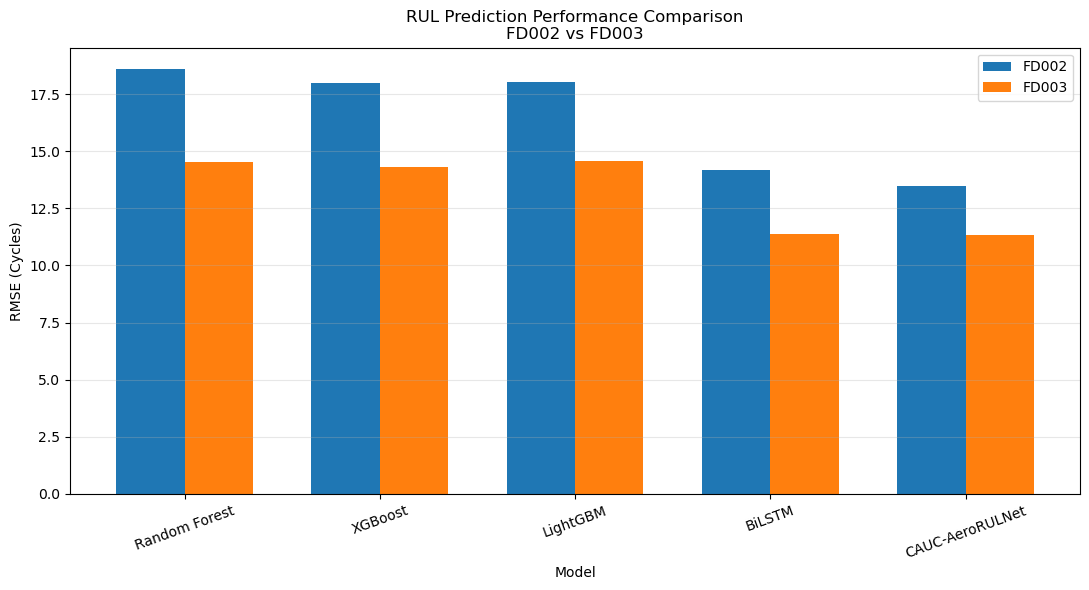

In [87]:
# ============================================================
# STEP 36
# RMSE MODEL COMPARISON GRAPH
# ============================================================

models = [
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "BiLSTM",
    "CAUC-AeroRULNet"
]


fd002_rmse_values = [
    18.596628,
    17.983665,
    18.047752,
    14.169504,
    13.462717
]


fd003_rmse_values = [
    14.524648,
    14.320447,
    14.583727,
    11.366003,
    11.314010
]


x = np.arange(
    len(models)
)

width = 0.35


plt.figure(
    figsize=(11, 6)
)


plt.bar(
    x - width / 2,
    fd002_rmse_values,
    width,
    label="FD002"
)


plt.bar(
    x + width / 2,
    fd003_rmse_values,
    width,
    label="FD003"
)


plt.xticks(
    x,
    models,
    rotation=20
)


plt.ylabel(
    "RMSE (Cycles)"
)


plt.xlabel(
    "Model"
)


plt.title(
    "RUL Prediction Performance Comparison\n"
    "FD002 vs FD003"
)


plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

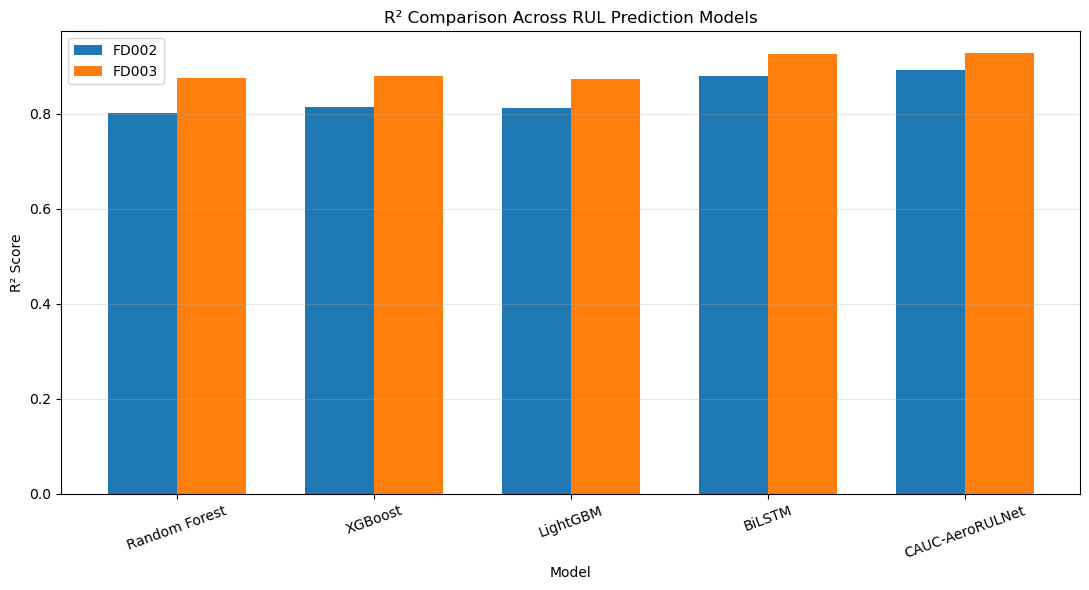

In [88]:
# ============================================================
# STEP 37
# R² MODEL COMPARISON GRAPH
# ============================================================

fd002_r2_values = [
    0.802265,
    0.815086,
    0.812955,
    0.880206,
    0.891859
]


fd003_r2_values = [
    0.875275,
    0.878758,
    0.873637,
    0.926313,
    0.926985
]


x = np.arange(
    len(models)
)

width = 0.35


plt.figure(
    figsize=(11, 6)
)


plt.bar(
    x - width / 2,
    fd002_r2_values,
    width,
    label="FD002"
)


plt.bar(
    x + width / 2,
    fd003_r2_values,
    width,
    label="FD003"
)


plt.xticks(
    x,
    models,
    rotation=20
)


plt.ylabel(
    "R² Score"
)


plt.xlabel(
    "Model"
)


plt.title(
    "R² Comparison Across RUL Prediction Models"
)


plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

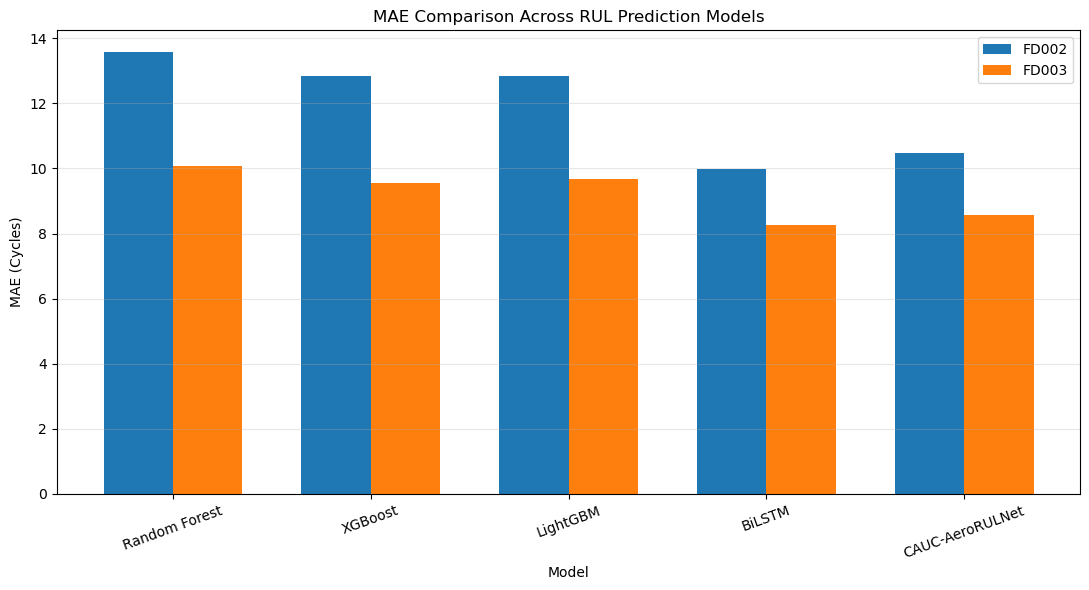

In [89]:
# ============================================================
# STEP 38
# MAE MODEL COMPARISON
# ============================================================

fd002_mae_values = [
    13.564615,
    12.826661,
    12.849766,
    9.973058,
    10.469964
]


fd003_mae_values = [
    10.061509,
    9.561207,
    9.683799,
    8.270232,
    8.556795
]


x = np.arange(
    len(models)
)

width = 0.35


plt.figure(
    figsize=(11, 6)
)


plt.bar(
    x - width / 2,
    fd002_mae_values,
    width,
    label="FD002"
)


plt.bar(
    x + width / 2,
    fd003_mae_values,
    width,
    label="FD003"
)


plt.xticks(
    x,
    models,
    rotation=20
)


plt.ylabel(
    "MAE (Cycles)"
)


plt.xlabel(
    "Model"
)


plt.title(
    "MAE Comparison Across RUL Prediction Models"
)


plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [90]:
# ============================================================
# STEP 39
# FINAL CAUC-AeroRULNet CONFIGURATION
# ============================================================

final_cauc_configuration = pd.DataFrame({

    "Parameter": [

        "Sequence Length",

        "Number of Sensors",

        "Learning Rate",

        "Dropout",

        "Conv Kernel Sizes",

        "Conv Filters",

        "Recurrent Layer",

        "GRU Units",

        "Temporal Attention",

        "Feature Attention",

        "Batch Size",

        "Loss Function",

        "Optimizer"
    ],


    "Final Value": [

        50,

        16,

        0.0005,

        0.20,

        "3, 5, 7",

        "32 per branch",

        "Bidirectional GRU",

        "64 per direction",

        "Yes",

        "Yes",

        256,

        "MSE",

        "Adam"
    ]

})


display(
    final_cauc_configuration
)

,Parameter,Final Value
0,Sequence Length,50
1,Number of Sensors,16
2,Learning Rate,0.0005
3,Dropout,0.2
4,Conv Kernel Sizes,"3, 5, 7"
5,Conv Filters,32 per branch
6,Recurrent Layer,Bidirectional GRU
7,GRU Units,64 per direction
8,Temporal Attention,Yes
9,Feature Attention,Yes


In [91]:
# ============================================================
# STEP 40
# SAVE FINAL EXPERIMENT RESULTS
# ============================================================

RESULT_DIR = (
    r"D:\IST\Aircraft_Engine_RUL\results"
)


os.makedirs(
    RESULT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# Save all model results
# ------------------------------------------------------------

all_model_results.to_csv(

    os.path.join(
        RESULT_DIR,
        "final_model_comparison.csv"
    ),

    index=False
)


# ------------------------------------------------------------
# Save CAUC configuration
# ------------------------------------------------------------

final_cauc_configuration.to_csv(

    os.path.join(
        RESULT_DIR,
        "final_cauc_configuration.csv"
    ),

    index=False
)


# ------------------------------------------------------------
# Save improvement results
# ------------------------------------------------------------

improvement_df.to_csv(

    os.path.join(
        RESULT_DIR,
        "cauc_vs_bilstm_improvement.csv"
    ),

    index=False
)


print(
    "✅ Final experimental results saved."
)

print(
    RESULT_DIR
)

✅ Final experimental results saved.
D:\IST\Aircraft_Engine_RUL\results


In [92]:
# ============================================================
# NOTEBOOK 04 - FINAL CHECKPOINT
# Save important artifacts for Notebook 05
# ============================================================

import os
import joblib

PROJECT_DIR = r"D:\IST\Aircraft_Engine_RUL"

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR,
    "checkpoints"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)


# ============================================================
# 1. FINAL CONFIGURATION
# ============================================================

final_project_config = {

    "sequence_length": 50,

    "num_sensors": 16,

    "learning_rate": 0.0005,

    "dropout": 0.20,

    "selected_sensors": [
        "sensor_11",
        "sensor_17",
        "sensor_4",
        "sensor_3",
        "sensor_2",
        "sensor_9",
        "sensor_13",
        "sensor_8",
        "sensor_14",
        "sensor_15",
        "sensor_12",
        "sensor_7",
        "sensor_20",
        "sensor_21",
        "sensor_6",
        "sensor_10"
    ]
}


joblib.dump(
    final_project_config,
    os.path.join(
        CHECKPOINT_DIR,
        "final_project_config.pkl"
    )
)


# ============================================================
# 2. FINAL RESULT TABLES
# ============================================================

joblib.dump(
    final_dl_comparison,
    os.path.join(
        CHECKPOINT_DIR,
        "final_dl_comparison.pkl"
    )
)


joblib.dump(
    all_model_results,
    os.path.join(
        CHECKPOINT_DIR,
        "all_model_results.pkl"
    )
)


joblib.dump(
    improvement_df,
    os.path.join(
        CHECKPOINT_DIR,
        "improvement_results.pkl"
    )
)


# ============================================================
# 3. FINAL VALIDATION METRICS
# ============================================================

final_validation_metrics = {

    "FD002": {

        "BiLSTM": {
            "MAE": 9.973058,
            "RMSE": 14.169504,
            "R2": 0.880206
        },

        "CAUC-AeroRULNet": {
            "MAE": 10.469964,
            "RMSE": 13.462717,
            "R2": 0.891859
        }
    },


    "FD003": {

        "BiLSTM": {
            "MAE": 8.270232,
            "RMSE": 11.366003,
            "R2": 0.926313
        },

        "CAUC-AeroRULNet": {
            "MAE": 8.556795,
            "RMSE": 11.314010,
            "R2": 0.926985
        }
    }
}


joblib.dump(
    final_validation_metrics,
    os.path.join(
        CHECKPOINT_DIR,
        "final_validation_metrics.pkl"
    )
)


print("=" * 65)
print("NOTEBOOK 04 FINAL CHECKPOINT")
print("=" * 65)

print("✅ Final configuration saved")
print("✅ Final DL comparison saved")
print("✅ All-model results saved")
print("✅ Improvement results saved")
print("✅ Validation metrics saved")

print("\nCheckpoint Directory:")
print(CHECKPOINT_DIR)

NOTEBOOK 04 FINAL CHECKPOINT
✅ Final configuration saved
✅ Final DL comparison saved
✅ All-model results saved
✅ Improvement results saved
✅ Validation metrics saved

Checkpoint Directory:
D:\IST\Aircraft_Engine_RUL\checkpoints


In [93]:
# ============================================================
# VERIFY FINAL CAUC MODEL VARIABLES
# ============================================================
# Goal:
# Identify the trained FD002 and FD003 models corresponding
# to the UNIVERSAL final configuration:
#
# LR      = 0.0005
# Dropout = 0.20
# ============================================================

possible_model_vars = [
    "cauc_lr_0005",
    "cauc_dropout_010",
    "cauc_dropout_030",
    "cauc_fd002_final",
    "cauc_fd003_final"
]

print("=" * 65)
print("MODEL VARIABLE CHECK")
print("=" * 65)

for var_name in possible_model_vars:

    if var_name in globals():

        model_obj = globals()[var_name]

        print(
            f"✅ {var_name:<25} "
            f"Parameters: {model_obj.count_params()}"
        )

    else:

        print(
            f"❌ {var_name:<25} NOT FOUND"
        )


# ------------------------------------------------------------
# Also inspect dictionary-based FD003 dropout models
# ------------------------------------------------------------

print("\nFD003 dropout model dictionary:")

if "fd003_dropout_models" in globals():

    print(
        "Available Dropouts:",
        list(fd003_dropout_models.keys())
    )

else:

    print(
        "❌ fd003_dropout_models NOT FOUND"
    )

MODEL VARIABLE CHECK
✅ cauc_lr_0005              Parameters: 97378
✅ cauc_dropout_010          Parameters: 97378
✅ cauc_dropout_030          Parameters: 97378
✅ cauc_fd002_final          Parameters: 186338
✅ cauc_fd003_final          Parameters: 97378

FD003 dropout model dictionary:
Available Dropouts: [0.2, 0.1]


In [94]:
# ============================================================
# SAVE FINAL UNIVERSAL CAUC-AeroRULNet MODELS
# ============================================================
# Universal configuration:
#
# Sequence Length = 50
# Sensors         = 16
# Learning Rate   = 0.0005
# Dropout         = 0.20
#
# FD002 model:
# cauc_lr_0005
#
# FD003 model:
# fd003_dropout_models[0.20]
# ============================================================

import os

MODEL_DIR = r"D:\IST\Aircraft_Engine_RUL\models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)


# ============================================================
# FD002 FINAL UNIVERSAL MODEL
# ============================================================

final_cauc_fd002 = cauc_lr_0005


# Safety check
if final_cauc_fd002.count_params() != 97378:
    raise ValueError(
        "FD002 final model architecture mismatch."
    )


FD002_FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "cauc_aerorulnet_fd002_final.keras"
)


final_cauc_fd002.save(
    FD002_FINAL_MODEL_PATH
)


# ============================================================
# FD003 FINAL UNIVERSAL MODEL
# ============================================================

final_cauc_fd003 = (
    fd003_dropout_models[0.20]
)


# Safety check
if final_cauc_fd003.count_params() != 97378:
    raise ValueError(
        "FD003 final model architecture mismatch."
    )


FD003_FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "cauc_aerorulnet_fd003_final.keras"
)


final_cauc_fd003.save(
    FD003_FINAL_MODEL_PATH
)


# ============================================================
# CONFIRM
# ============================================================

print("=" * 65)
print("FINAL UNIVERSAL CAUC MODELS SAVED")
print("=" * 65)

print("\nFD002")
print("Model:", type(final_cauc_fd002))
print("Parameters:", final_cauc_fd002.count_params())
print("Path:", FD002_FINAL_MODEL_PATH)

print("\nFD003")
print("Model:", type(final_cauc_fd003))
print("Parameters:", final_cauc_fd003.count_params())
print("Path:", FD003_FINAL_MODEL_PATH)

FINAL UNIVERSAL CAUC MODELS SAVED

FD002
Model: <class 'keras.src.models.functional.Functional'>
Parameters: 97378
Path: D:\IST\Aircraft_Engine_RUL\models\cauc_aerorulnet_fd002_final.keras

FD003
Model: <class 'keras.src.models.functional.Functional'>
Parameters: 97378
Path: D:\IST\Aircraft_Engine_RUL\models\cauc_aerorulnet_fd003_final.keras


In [95]:
# ============================================================
# VERIFY SAVED FINAL MODELS
# ============================================================

loaded_fd002_model = tf.keras.models.load_model(
    FD002_FINAL_MODEL_PATH,
    safe_mode=False
)

loaded_fd003_model = tf.keras.models.load_model(
    FD003_FINAL_MODEL_PATH,
    safe_mode=False
)


print("FD002 Loaded Params:",
      loaded_fd002_model.count_params())

print("FD003 Loaded Params:",
      loaded_fd003_model.count_params())


if (
    loaded_fd002_model.count_params() == 97378
    and
    loaded_fd003_model.count_params() == 97378
):
    print(
        "\n✅ Both final CAUC models verified successfully."
    )

else:
    print(
        "\n❌ Model verification failed."
    )

NotImplementedError: Exception encountered when calling Lambda.call().

[1mWe could not automatically infer the shape of the Lambda's output. Please specify the `output_shape` argument for this Lambda layer.[0m

Arguments received by Lambda.call():
  • args=('<KerasTensor shape=(None, 50, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_44>',)
  • kwargs={'mask': 'None'}

In [96]:
# ============================================================
# SERIALIZATION-SAFE TEMPORAL SUM LAYER
# ============================================================
# Problem:
# Anonymous Lambda layers can create model-loading problems.
#
# Solution:
# Replace:
# Lambda(lambda x: tf.reduce_sum(x, axis=1))
#
# with a proper custom Keras layer.
#
# This layer has NO trainable parameters, therefore it does
# not change the learned model behavior.
# ============================================================

@tf.keras.utils.register_keras_serializable(
    package="CAUC"
)
class TemporalSum(tf.keras.layers.Layer):

    def call(self, inputs):
        """
        Sum the weighted temporal sequence across
        the timestep dimension.

        Input:
            (batch, 50, 128)

        Output:
            (batch, 128)
        """

        return tf.reduce_sum(
            inputs,
            axis=1
        )


    def compute_output_shape(
        self,
        input_shape
    ):
        """
        Explicitly tell Keras the output shape.
        """

        return (
            input_shape[0],
            input_shape[2]
        )


    def get_config(self):
        """
        Required for reliable Keras serialization.
        """

        config = super().get_config()

        return config


print(
    "✅ Serialization-safe TemporalSum layer ready."
)

✅ Serialization-safe TemporalSum layer ready.


In [97]:
# ============================================================
# SERIALIZATION-SAFE FINAL CAUC-AeroRULNet BUILDER
# ============================================================
# Architecture remains identical to the trained model.
#
# The ONLY structural serialization change is:
#
# Anonymous Lambda → TemporalSum custom layer
#
# No trainable component is changed.
# ============================================================

def build_final_serializable_cauc(
    sequence_length=50,
    num_sensor_features=16,
    learning_rate=0.0005,
    dropout_rate=0.20
):

    # ========================================================
    # INPUT
    # ========================================================

    sensor_input = tf.keras.layers.Input(
        shape=(
            sequence_length,
            num_sensor_features
        ),
        name="sensor_sequence_input"
    )


    # ========================================================
    # MULTI-SCALE TEMPORAL CONVOLUTIONS
    # ========================================================

    branch_3 = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu",
        name="tcn_kernel_3"
    )(sensor_input)


    branch_5 = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=5,
        padding="same",
        activation="relu",
        name="tcn_kernel_5"
    )(sensor_input)


    branch_7 = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=7,
        padding="same",
        activation="relu",
        name="tcn_kernel_7"
    )(sensor_input)


    # ========================================================
    # MULTI-SCALE FUSION
    # ========================================================

    x = tf.keras.layers.Concatenate(
        axis=-1,
        name="multi_scale_fusion"
    )([
        branch_3,
        branch_5,
        branch_7
    ])


    x = tf.keras.layers.BatchNormalization(
        name="multi_scale_batchnorm"
    )(x)


    x = tf.keras.layers.Dropout(
        dropout_rate,
        name="multi_scale_dropout"
    )(x)


    # ========================================================
    # BiGRU
    # ========================================================

    x = tf.keras.layers.Bidirectional(

        tf.keras.layers.GRU(
            64,
            return_sequences=True
        ),

        name="bidirectional_gru"

    )(x)


    x = tf.keras.layers.Dropout(
        dropout_rate,
        name="bigru_dropout"
    )(x)


    # ========================================================
    # TEMPORAL ATTENTION
    # ========================================================

    temporal_scores = tf.keras.layers.Dense(
        1,
        name="temporal_attention_scores"
    )(x)


    temporal_weights = tf.keras.layers.Softmax(
        axis=1,
        name="temporal_attention_weights"
    )(temporal_scores)


    weighted_sequence = tf.keras.layers.Multiply(
        name="temporal_weighted_sequence"
    )([
        x,
        temporal_weights
    ])


    # ========================================================
    # SERIALIZATION-SAFE TEMPORAL AGGREGATION
    # ========================================================

    temporal_context = TemporalSum(
        name="temporal_context"
    )(weighted_sequence)


    # ========================================================
    # FEATURE ATTENTION
    # ========================================================

    feature_attention = tf.keras.layers.Dense(
        128,
        activation="sigmoid",
        name="feature_attention_weights"
    )(temporal_context)


    feature_context = tf.keras.layers.Multiply(
        name="feature_attention"
    )([
        temporal_context,
        feature_attention
    ])


    # ========================================================
    # REGRESSION HEAD
    # ========================================================

    x = tf.keras.layers.Dense(
        64,
        activation="relu",
        name="dense_64"
    )(feature_context)


    x = tf.keras.layers.Dropout(
        dropout_rate,
        name="dense_dropout"
    )(x)


    x = tf.keras.layers.Dense(
        32,
        activation="relu",
        name="dense_32"
    )(x)


    output = tf.keras.layers.Dense(
        1,
        activation="linear",
        name="rul_prediction"
    )(x)


    # ========================================================
    # MODEL
    # ========================================================

    model = tf.keras.Model(
        inputs=sensor_input,
        outputs=output,
        name="CAUC_AeroRULNet"
    )


    # ========================================================
    # COMPILE
    # ========================================================

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),

        loss="mse",

        metrics=["mae"]
    )


    return model

In [98]:
# ============================================================
# CREATE SERIALIZATION-SAFE FD002 FINAL MODEL
# ============================================================

final_cauc_fd002_safe = (
    build_final_serializable_cauc(

        sequence_length=50,

        num_sensor_features=16,

        learning_rate=0.0005,

        dropout_rate=0.20
    )
)


print(
    "New FD002 Parameters:",
    final_cauc_fd002_safe.count_params()
)


print(
    "Original FD002 Parameters:",
    cauc_lr_0005.count_params()
)

New FD002 Parameters: 97378
Original FD002 Parameters: 97378


In [99]:
# ============================================================
# TRANSFER TRAINED FD002 WEIGHTS
# ============================================================
# No retraining occurs here.
# We simply transfer already learned parameters.
# ============================================================

final_cauc_fd002_safe.set_weights(
    cauc_lr_0005.get_weights()
)

print(
    "✅ FD002 trained weights transferred successfully."
)

✅ FD002 trained weights transferred successfully.


In [100]:
# ============================================================
# VERIFY FD002 WEIGHT TRANSFER
# ============================================================

verification_X = (
    X_sensor_val_fd002[:100]
)


# Original trained model
old_predictions_fd002 = (
    cauc_lr_0005.predict(
        verification_X,
        verbose=0
    ).reshape(-1)
)


# New serialization-safe model
new_predictions_fd002 = (
    final_cauc_fd002_safe.predict(
        verification_X,
        verbose=0
    ).reshape(-1)
)


max_difference_fd002 = np.max(
    np.abs(
        old_predictions_fd002
        -
        new_predictions_fd002
    )
)


print(
    "Maximum FD002 Prediction Difference:",
    max_difference_fd002
)

Maximum FD002 Prediction Difference: 0.0


In [101]:
# ============================================================
# CREATE SERIALIZATION-SAFE FD003 FINAL MODEL
# ============================================================

final_cauc_fd003_safe = (
    build_final_serializable_cauc(

        sequence_length=50,

        num_sensor_features=16,

        learning_rate=0.0005,

        dropout_rate=0.20
    )
)


print(
    "New FD003 Parameters:",
    final_cauc_fd003_safe.count_params()
)


print(
    "Original FD003 Parameters:",
    fd003_dropout_models[0.20].count_params()
)

New FD003 Parameters: 97378
Original FD003 Parameters: 97378


In [102]:
# ============================================================
# TRANSFER TRAINED FD003 WEIGHTS
# ============================================================

final_cauc_fd003_safe.set_weights(

    fd003_dropout_models[
        0.20
    ].get_weights()

)


print(
    "✅ FD003 trained weights transferred successfully."
)

✅ FD003 trained weights transferred successfully.


In [103]:
# ============================================================
# VERIFY FD003 WEIGHT TRANSFER
# ============================================================

verification_X_fd003 = (
    X_sensor_val_fd003[:100]
)


old_predictions_fd003 = (

    fd003_dropout_models[0.20]

    .predict(
        verification_X_fd003,
        verbose=0
    )

    .reshape(-1)
)


new_predictions_fd003 = (

    final_cauc_fd003_safe

    .predict(
        verification_X_fd003,
        verbose=0
    )

    .reshape(-1)
)


max_difference_fd003 = np.max(

    np.abs(

        old_predictions_fd003

        -

        new_predictions_fd003

    )
)


print(
    "Maximum FD003 Prediction Difference:",
    max_difference_fd003
)

Maximum FD003 Prediction Difference: 0.0


In [104]:
# ============================================================
# SAVE SERIALIZATION-SAFE FINAL MODELS
# ============================================================

MODEL_DIR = (
    r"D:\IST\Aircraft_Engine_RUL\models"
)


FD002_FINAL_SAFE_PATH = os.path.join(

    MODEL_DIR,

    "cauc_aerorulnet_fd002_final.keras"
)


FD003_FINAL_SAFE_PATH = os.path.join(

    MODEL_DIR,

    "cauc_aerorulnet_fd003_final.keras"
)


# ------------------------------------------------------------
# Save FD002
# ------------------------------------------------------------

final_cauc_fd002_safe.save(
    FD002_FINAL_SAFE_PATH
)


# ------------------------------------------------------------
# Save FD003
# ------------------------------------------------------------

final_cauc_fd003_safe.save(
    FD003_FINAL_SAFE_PATH
)


print(
    "✅ Serialization-safe models saved."
)


print(
    "\nFD002:"
)

print(
    FD002_FINAL_SAFE_PATH
)


print(
    "\nFD003:"
)

print(
    FD003_FINAL_SAFE_PATH
)

✅ Serialization-safe models saved.

FD002:
D:\IST\Aircraft_Engine_RUL\models\cauc_aerorulnet_fd002_final.keras

FD003:
D:\IST\Aircraft_Engine_RUL\models\cauc_aerorulnet_fd003_final.keras


In [105]:
# ============================================================
# FINAL MODEL LOAD-BACK VERIFICATION
# ============================================================

loaded_fd002_model = (
    tf.keras.models.load_model(
        FD002_FINAL_SAFE_PATH
    )
)


loaded_fd003_model = (
    tf.keras.models.load_model(
        FD003_FINAL_SAFE_PATH
    )
)


print("=" * 65)

print(
    "FINAL MODEL LOAD VERIFICATION"
)

print("=" * 65)


print(
    "FD002 Loaded Parameters:",
    loaded_fd002_model.count_params()
)


print(
    "FD003 Loaded Parameters:",
    loaded_fd003_model.count_params()
)


if (
    loaded_fd002_model.count_params() == 97378
    and
    loaded_fd003_model.count_params() == 97378
):

    print(
        "\n✅ BOTH FINAL MODELS LOAD SUCCESSFULLY."
    )

else:

    print(
        "\n❌ Verification failed."
    )

D:\Anaconda\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 50 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


FINAL MODEL LOAD VERIFICATION
FD002 Loaded Parameters: 97378
FD003 Loaded Parameters: 97378

✅ BOTH FINAL MODELS LOAD SUCCESSFULLY.


D:\Anaconda\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_2', because it has 50 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
